# AI Cybersecurity Digital Twin
**Project 16 · AI-Driven Predictive Cyber Defense**  
**Author:** Shaharia Abdullah Rakib

A virtual enterprise network is mirrored by an AI-driven digital twin that continuously cycles through five stages:

**Current Network State → Digital Twin → Attack Simulation → Risk Prediction → Defense Strategy**

| Stage | What this notebook does | Section |
|---|---|---|
| Current Network State | Multi-day, multi-family CSE-CIC-IDS2018 data; leakage-safe pipeline; chronological and leave-one-day-out evaluation; natural class imbalance; baseline models with significance tests | §1 – §5 |
| Risk Prediction | Calibrated probabilities, cost-based thresholds, SHAP / LIME explanations, window-based temporal forecasting | §6 – §8 |
| Digital Twin | 14-node enterprise topology, formal twin definition and fidelity metrics | §9, §11 |
| Attack Simulation | CVSS-derived risk propagation, sensitivity analysis, attack-scenario library | §9, §10 |
| Defense Strategy | Fixed thresholds vs twin look-ahead vs deep RL (DQN), ablation study | §10, §12 |
| Robustness and deployment | Adversarial tests, streaming latency, live Mininet/OVS path, reproducibility | §13 – §16 |
| Conclusion | Findings, limitations and future work | §17 |

**Honesty notes (read before citing any number):**
* Everything here runs in Colab. Anything labelled *simulated* is a software stand-in, **not** a measurement on a real network.
* Topology parameters (criticality, CVSS-like scores, severity weights, action costs) are **assumptions** to be justified or replaced with real scan/asset data.
* Set `CFG["SMOKE_TEST"]=True` only to check that the notebook runs end-to-end on tiny synthetic data. Those numbers mean nothing.


In [31]:
!pip -q install lightgbm xgboost shap lime imbalanced-learn statsmodels

In [32]:
import os, sys, time, json, math, random, warnings, subprocess, urllib.request, platform, gc, itertools
from collections import defaultdict, OrderedDict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except Exception:
    display = print

CFG = dict(
    SEED=42,
    SMOKE_TEST=False,                 # True = tiny synthetic CIC-style CSVs, ONLY to verify the code runs
    DATA_DIR="/content/cic2018",
    # Days to use. Each family appears on >=1 day. 'Tue-20' (DDoS-LOIC-HTTP, ~GBs) is optional.
    DAYS=["Fri-02", "Wed-14", "Thu-15", "Wed-21", "Wed-28"],
    MAX_PER_FAMILY_PER_DAY=5000,      # cap per (day, label family) to fit Colab RAM
    TEST_FRAC_TIME=0.30,              # chronological hold-out = last 30 % of each day
    GAP_SECONDS=120,                  # purge gap between train and test (near-duplicate flows)
    N_FEATURES=40,                    # MI top-k (validate with the curve in §3)
    N_SEEDS=3,                        # repeated runs for mean ± std
    STREAM_FRAC=0.10,                 # fraction of Fri-02 kept (time-ordered) for temporal module
    RUN_LODO=True,                    # leave-one-day-out (slowest block)
    OUT_DIR="/content/dt_outputs",
)
if CFG["SMOKE_TEST"]:
    CFG.update(DATA_DIR="/tmp/cic_smoke", MAX_PER_FAMILY_PER_DAY=1500, N_SEEDS=2, N_FEATURES=20, STREAM_FRAC=1.0, OUT_DIR="/tmp/dt_outputs")
os.makedirs(CFG["OUT_DIR"], exist_ok=True); os.makedirs(CFG["DATA_DIR"], exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); os.environ["PYTHONHASHSEED"] = str(s)
seed_everything(CFG["SEED"])
RNG = np.random.default_rng(CFG["SEED"])
RESULTS = {}                           # every table we want to save goes here
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)

Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3


In [33]:
import os
os.makedirs("/content/cic2018", exist_ok=True)
base = "http://cse-cic-ids2018.s3.amazonaws.com/Processed%20Traffic%20Data%20for%20ML%20Algorithms/"
files = ["Friday-02-03-2018", "Wednesday-14-02-2018", "Thursday-15-02-2018", "Wednesday-21-02-2018", "Wednesday-28-02-2018"]
for f in files:
    !wget -q -c -P /content/cic2018 "{base}{f}_TrafficForML_CICFlowMeter.csv"
!ls -lh /content/cic2018

import pandas as pd
for f in files:
    d = pd.read_csv(f"/content/cic2018/{f}_TrafficForML_CICFlowMeter.csv", nrows=200000, low_memory=False)
    d.columns = [c.strip() for c in d.columns]
    print(f, d.shape[1], "columns | labels:", d["Label"].value_counts().to_dict())
    print("   time range:", d["Timestamp"].iloc[0], "...", d["Timestamp"].iloc[-1])


total 2.0G
-rw-r--r-- 1 root root 337M Oct 11  2018 Friday-02-03-2018_TrafficForML_CICFlowMeter.csv
-rw-r--r-- 1 root root 319M Nov  1 03:33 Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
-rw-r--r-- 1 root root 103M Nov  1 03:33 Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv
-rw-r--r-- 1 root root 359M Oct 11  2018 Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv
-rw-r--r-- 1 root root 342M Oct 11  2018 Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv
-rw-r--r-- 1 root root 314M Oct 11  2018 Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv
-rw-r--r-- 1 root root 200M Oct 11  2018 Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv
Friday-02-03-2018 80 columns | labels: {'Bot': 162906, 'Benign': 37094}
   time range: 02/03/2018 08:47:38 ... 02/03/2018 08:51:59
Wednesday-14-02-2018 80 columns | labels: {'FTP-BruteForce': 179244, 'SSH-Bruteforce': 20490, 'Benign': 266}
   time range: 14/02/2018 08:31:01 ... 14/02/2018 02:04:56
Thursday-15-02-2018 80 columns | labels: {'Benign': 14

## 1. Data — multi-day, multi-family CSE-CIC-IDS2018
A single day with only Benign vs Bot is too narrow. Here every day is loaded with a **per-(day, family) cap** so Colab does not run out of RAM.
Files are fetched from the Hugging Face mirror and, as fallback, the public AWS Open Data bucket (not every filename was verified — if a download fails, upload the CSV to `DATA_DIR` manually or from Drive).

In [34]:
DAY_FILES = {
    "Wed-14": "Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv",   # FTP/SSH brute force
    "Thu-15": "Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv",    # DoS GoldenEye / Slowloris
    "Fri-16": "Friday-16-02-2018_TrafficForML_CICFlowMeter.csv",      # DoS SlowHTTPTest / Hulk
    "Tue-20": "Tuesday-20-02-2018_TrafficForML_CICFlowMeter.csv",     # DDoS LOIC-HTTP (very large)
    "Wed-21": "Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv",   # DDoS LOIC-UDP / HOIC
    "Thu-22": "Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv",    # Web brute force / XSS / SQLi
    "Fri-23": "Friday-23-02-2018_TrafficForML_CICFlowMeter.csv",      # Web attacks
    "Wed-28": "Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv",   # Infiltration
    "Thu-01": "Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv",    # Infiltration
    "Fri-02": "Friday-02-03-2018_TrafficForML_CICFlowMeter.csv",      # Bot
}
SOURCES = ["https://huggingface.co/datasets/c01dsnap/CIC-IDS2018/resolve/main/",
           "https://cse-cic-ids2018.s3.ca-central-1.amazonaws.com/Processed%20Traffic%20Data%20for%20ML%20Algorithms/"]
ID_COLS = {"Flow ID", "Src IP", "Dst IP", "Src Port", "Source IP", "Destination IP"}   # never used as features
FAMILIES = ["Benign", "Bot", "BruteForce", "DoS", "DDoS", "WebAttack", "Infiltration"]

def map_family(label):
    l = str(label).strip().lower()
    if l == "benign": return "Benign"
    if "bot" in l: return "Bot"
    if "sql" in l or "xss" in l or "-web" in l or "web" in l: return "WebAttack"
    if "ddos" in l: return "DDoS"
    if "dos" in l: return "DoS"
    if "brute" in l: return "BruteForce"
    if "infil" in l: return "Infiltration"
    return None                                   # repeated header rows etc.

def ensure_day_file(day):
    path = os.path.join(CFG["DATA_DIR"], DAY_FILES[day])
    if os.path.exists(path) and os.path.getsize(path) > 1e5: return path
    for base in SOURCES:
        try:
            print(f"  downloading {DAY_FILES[day]} from {base.split('/')[2]} ...")
            urllib.request.urlretrieve(base + DAY_FILES[day], path)
            if os.path.getsize(path) > 1e5: return path
        except Exception as e:
            print("   failed:", str(e)[:80])
            if os.path.exists(path): os.remove(path)
    return None

def load_day(day, path, max_per_family, seed, keep_all_fraction=None):
    """Chunked read. Keeps <=max_per_family rows per family (time-stratified by chunk).
       keep_all_fraction=f keeps a uniform fraction f of ALL rows (time order preserved) -> used for the temporal stream."""
    rng = np.random.default_rng(seed); parts = []
    for chunk in pd.read_csv(path, chunksize=200_000, low_memory=False, usecols=lambda c: c not in ID_COLS):
        chunk.columns = [c.strip() for c in chunk.columns]
        chunk = chunk[chunk["Label"].astype(str) != "Label"]                # repeated header rows
        chunk["Family"] = chunk["Label"].map(map_family)
        chunk = chunk.dropna(subset=["Family"])
        if keep_all_fraction is not None:
            chunk = chunk.sample(frac=keep_all_fraction, random_state=int(rng.integers(1e9)))
        else:
            chunk = pd.concat([g.sample(n=min(len(g), max_per_family), random_state=int(rng.integers(1e9)))
                               for _, g in chunk.groupby("Family")])
        parts.append(chunk)
    df = pd.concat(parts, ignore_index=True)
    if keep_all_fraction is None:
        df = pd.concat([g.sample(n=min(len(g), max_per_family), random_state=seed) for _, g in df.groupby("Family")], ignore_index=True)
    df["ts"] = pd.to_datetime(df["Timestamp"], format="%d/%m/%Y %H:%M:%S", errors="coerce")
    if df["ts"].isna().mean() > 0.5: df["ts"] = pd.to_datetime(df["Timestamp"], errors="coerce", dayfirst=True)
        # CIC-IDS2018 timestamps are 12-hour clock without AM/PM: 01:00-07:59 are really 13:00-19:59
    df["ts"] = df["ts"].where(df["ts"].dt.hour >= 8, df["ts"] + pd.Timedelta(hours=12))

    df["ts_sec"] = (df["ts"] - df["ts"].dt.normalize()).dt.total_seconds()
    df = df.drop(columns=["Timestamp"])
    num = [c for c in df.columns if c not in ("Label", "Family", "ts")]
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan)
    df[num] = df[num].astype("float32")
    df["Day"] = day
    return df.sort_values("ts").reset_index(drop=True)

# ---------- smoke-test generator (CIC-style CSVs; ONLY for checking that the code runs) ----------
def write_smoke_csvs():
    rng = np.random.default_rng(0)
    cols = ["Dst Port","Protocol","Timestamp","Flow Duration","Tot Fwd Pkts","Tot Bwd Pkts","TotLen Fwd Pkts","TotLen Bwd Pkts",
            "Fwd Pkt Len Max","Fwd Pkt Len Min","Fwd Pkt Len Mean","Fwd Pkt Len Std","Bwd Pkt Len Max","Bwd Pkt Len Min",
            "Bwd Pkt Len Mean","Bwd Pkt Len Std","Flow Byts/s","Flow Pkts/s","Flow IAT Mean","Flow IAT Std","Flow IAT Max",
            "Flow IAT Min","Fwd IAT Tot","Fwd IAT Mean","Fwd IAT Max","Fwd IAT Min","Fwd Pkts/s","Bwd Pkts/s","Pkt Len Mean",
            "Pkt Len Std","SYN Flag Cnt","ACK Flag Cnt","Init Fwd Win Byts","Init Bwd Win Byts","Label"]
    day_labels = {"Fri-02": ["Bot"], "Wed-14": ["FTP-BruteForce", "SSH-Bruteforce"], "Thu-15": ["DoS attacks-GoldenEye", "DoS attacks-Slowloris"],
                  "Fri-16": ["DoS attacks-Hulk"], "Wed-21": ["DDOS attack-HOIC"], "Thu-22": ["Brute Force -Web", "SQL Injection"],
                  "Fri-23": ["Brute Force -XSS"], "Wed-28": ["Infilteration"], "Thu-01": ["Infilteration"]}
    shift = {"Bot": 1, "FTP-BruteForce": 2, "SSH-Bruteforce": 2.2, "DoS attacks-GoldenEye": 3, "DoS attacks-Slowloris": 3.3, "DoS attacks-Hulk": 3.6,
             "DDOS attack-HOIC": 4, "Brute Force -Web": 1.6, "SQL Injection": 1.8, "Brute Force -XSS": 1.7, "Infilteration": 0.9}
    port = {"Bot": 8080, "FTP-BruteForce": 21, "SSH-Bruteforce": 22, "DoS attacks-GoldenEye": 80, "DoS attacks-Slowloris": 80, "DoS attacks-Hulk": 80,
            "DDOS attack-HOIC": 80, "Brute Force -Web": 80, "SQL Injection": 80, "Brute Force -XSS": 80, "Infilteration": 443}
    for day, labs in day_labels.items():
        n_ben, n_att = 5000, 1200
        rows = []
        day0 = pd.Timestamp("2018-02-14")
        def block(label, n, t0, t1):
            s = shift.get(label, 0.0); is_att = label != "Benign"
            d = pd.DataFrame(index=range(n))
            d["Dst Port"] = rng.choice([80, 443, 53, 22, 8080, 3389], n) if not is_att else np.where(rng.random(n) < 0.7, port[label], rng.integers(1, 65000, n))
            d["Protocol"] = rng.choice([6, 17, 0], n, p=[.8, .18, .02])
            t = np.sort(rng.uniform(t0, t1, n)); d["Timestamp"] = [(day0 + pd.Timedelta(seconds=float(x))).strftime("%d/%m/%Y %H:%M:%S") for x in t]
            d["Flow Duration"] = np.exp(rng.normal(11 - 0.4 * s, 2, n)); d["Tot Fwd Pkts"] = rng.poisson(8 + 6 * s, n) + 1; d["Tot Bwd Pkts"] = rng.poisson(8 - s, n)
            d["TotLen Fwd Pkts"] = d["Tot Fwd Pkts"] * np.exp(rng.normal(5.2 - 0.2 * s, .6, n)); d["TotLen Bwd Pkts"] = d["Tot Bwd Pkts"] * np.exp(rng.normal(5.5 - 0.3 * s, .8, n))
            for p in ("Fwd", "Bwd"):
                m = np.exp(rng.normal(5 - 0.2 * s, .7, n)); d[f"{p} Pkt Len Mean"] = m; d[f"{p} Pkt Len Max"] = m * 2; d[f"{p} Pkt Len Min"] = m * .2; d[f"{p} Pkt Len Std"] = m * .5
            d["Flow Byts/s"] = (d["TotLen Fwd Pkts"] + d["TotLen Bwd Pkts"]) / (d["Flow Duration"] / 1e6 + 1e-3)
            d["Flow Pkts/s"] = (d["Tot Fwd Pkts"] + d["Tot Bwd Pkts"]) / (d["Flow Duration"] / 1e6 + 1e-3)
            d["Fwd Pkts/s"] = d["Flow Pkts/s"] * .6; d["Bwd Pkts/s"] = d["Flow Pkts/s"] * .4
            for c in ("Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min", "Fwd IAT Tot", "Fwd IAT Mean", "Fwd IAT Max", "Fwd IAT Min"):
                d[c] = np.exp(rng.normal(9 - 0.3 * s, 1.5, n))
            d["Pkt Len Mean"] = (d["Fwd Pkt Len Mean"] + d["Bwd Pkt Len Mean"]) / 2; d["Pkt Len Std"] = d["Fwd Pkt Len Std"]
            d["SYN Flag Cnt"] = rng.integers(0, 2, n); d["ACK Flag Cnt"] = rng.integers(0, 2, n)
            d["Init Fwd Win Byts"] = rng.choice([-1, 8192, 29200, 65535], n); d["Init Bwd Win Byts"] = rng.choice([-1, 229, 26883, 65535], n)
            d.loc[rng.random(n) < 0.002, "Flow Byts/s"] = np.inf; d.loc[rng.random(n) < 0.002, "Flow Pkts/s"] = np.nan
            d["Label"] = label; return d[cols]
        day_len = 9 * 3600
        parts = [block("Benign", n_ben, 8 * 3600 - 8 * 3600 + 3600, day_len)]
        for i, lab in enumerate(labs):                                  # two attack bursts per day (for the temporal module)
            parts.append(block(lab, n_att // 2, 3 * 3600 + i * 3000, 3 * 3600 + i * 3000 + 1500))
            parts.append(block(lab, n_att // 2, 6 * 3600 + i * 3000, 6 * 3600 + i * 3000 + 1500))
        out = pd.concat(parts).sort_values("Timestamp", key=lambda s: pd.to_datetime(s, format="%d/%m/%Y %H:%M:%S"))
        out.to_csv(os.path.join(CFG["DATA_DIR"], DAY_FILES[day]), index=False)
        hdr = pd.DataFrame([cols], columns=cols)                         # a repeated header row, as in the real files
        hdr.to_csv(os.path.join(CFG["DATA_DIR"], DAY_FILES[day]), mode="a", header=False, index=False)

if CFG["SMOKE_TEST"]:
    write_smoke_csvs(); print("SMOKE TEST MODE: synthetic CSVs written to", CFG["DATA_DIR"])

day_frames = {}
for day in CFG["DAYS"]:
    p = ensure_day_file(day)
    if p is None: print(f"  !! {day} unavailable -> skipped (upload the CSV to {CFG['DATA_DIR']})"); continue
    day_frames[day] = load_day(day, p, CFG["MAX_PER_FAMILY_PER_DAY"], CFG["SEED"])
    print(f"{day}: {len(day_frames[day]):>7,} rows | " + ", ".join(f"{k}={v}" for k, v in day_frames[day]['Family'].value_counts().items()))
assert len(day_frames) >= 2, "Need at least 2 days for cross-day evaluation."
DF = pd.concat(day_frames.values(), ignore_index=True)
DF["y"] = (DF["Family"] != "Benign").astype(int)
META = {"Label", "Family", "Day", "ts", "ts_sec", "y"}
RAW_COLS = [c for c in DF.columns if c not in META - {"ts_sec"}]       # raw model inputs (incl. Dst Port, Protocol, ts_sec)
print("\nPooled:", DF.shape, "| families:", DF["Family"].value_counts().to_dict())
print("Raw input columns:", len(RAW_COLS))

Fri-02:  10,000 rows | Benign=5000, Bot=5000
Wed-14:  10,000 rows | Benign=5000, BruteForce=5000
Thu-15:  10,000 rows | Benign=5000, DoS=5000
Wed-21:  10,000 rows | Benign=5000, DDoS=5000
Wed-28:  10,000 rows | Benign=5000, Infiltration=5000

Pooled: (50000, 84) | families: {'Benign': 25000, 'Bot': 5000, 'BruteForce': 5000, 'DoS': 5000, 'DDoS': 5000, 'Infiltration': 5000}
Raw input columns: 79


## 2. Leakage-safe pipeline, metrics and splits
**Problem in the legacy pipeline:** Yeo-Johnson, RobustScaler and Mutual-Information selection were fitted on the *whole* dataset before the train/test split, and `Dst Port` (a possible label shortcut) was the top MI feature.
**Fix:** deterministic feature engineering stays outside; *every fitted step* (imputer → power transform → scaler → MI selection → classifier) lives in one pipeline fitted on training rows only.

In [35]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, RobustScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, balanced_accuracy_score,
                             roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss, classification_report)
import lightgbm as lgb
import xgboost as xgb

SHORTCUTS = ["Dst Port", "ts_sec"]          # suspected label shortcuts (port / time-of-day)

def flows_to_frame(flows):
    """list[dict] | dict | DataFrame -> DataFrame with all RAW_COLS (missing -> NaN, imputed later)."""
    if isinstance(flows, dict): flows = [flows]
    X = pd.DataFrame(flows) if not isinstance(flows, pd.DataFrame) else flows.copy()
    if "ts_sec" not in X.columns and "Timestamp" in X.columns:
        t = pd.to_datetime(X["Timestamp"], errors="coerce", dayfirst=True)
        X["ts_sec"] = (t - t.dt.normalize()).dt.total_seconds()
    return X.reindex(columns=RAW_COLS).apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).astype("float64")

def make_X(flows, use_shortcuts=True):
    """Deterministic (non-fitted) feature engineering => no leakage possible."""
    X = flows_to_frame(flows)
    fp, bp, fb, bb = X["Tot Fwd Pkts"], X["Tot Bwd Pkts"], X["TotLen Fwd Pkts"], X["TotLen Bwd Pkts"]
    X["Total_Pkts"] = fp + bp; X["Total_Bytes"] = fb + bb
    X["Fwd_Bwd_Pkt_Ratio"] = fp / (bp + 1); X["Fwd_Bwd_Byte_Ratio"] = fb / (bb + 1)
    X["Mean_Pkt_Size"] = X["Total_Bytes"] / (X["Total_Pkts"] + 1)
    for p in (0, 6, 17): X[f"Proto_{p}"] = (X["Protocol"] == p).astype(float)
    X = X.drop(columns=["Protocol"])
    if not use_shortcuts: X = X.drop(columns=[c for c in SHORTCUTS if c in X.columns])
    return X.replace([np.inf, -np.inf], np.nan)

class FastPowerTransformer(PowerTransformer):
    """Yeo-Johnson lambdas estimated on a <=50k-row subsample (speed); transform is still applied to all rows."""
    def fit(self, X, y=None):
        X = np.asarray(X); idx = np.random.default_rng(0).choice(len(X), min(len(X), 50000), replace=False)
        return super().fit(X[idx])
    def fit_transform(self, X, y=None): return self.fit(X).transform(X)
    def transform(self, X): return np.clip(np.nan_to_num(super().transform(X), nan=0.0, posinf=1e6, neginf=-1e6), -1e6, 1e6)

class MISelector(BaseEstimator, TransformerMixin):
    """Mutual-information top-k, fitted on TRAINING rows only (subsampled for speed)."""
    def __init__(self, k=40, max_rows=20000, random_state=42): self.k, self.max_rows, self.random_state = k, max_rows, random_state
    def fit(self, X, y):
        X = np.asarray(X); y = np.asarray(y)
        idx = np.random.default_rng(self.random_state).choice(len(X), min(len(X), self.max_rows), replace=False)
        self.scores_ = mutual_info_classif(X[idx], y[idx], random_state=self.random_state)
        self.idx_ = np.sort(np.argsort(self.scores_)[::-1][:min(self.k, X.shape[1])]); return self
    def transform(self, X): return np.asarray(X)[:, self.idx_]

def make_preproc(kind="tree", k=None, seed=42):
    k = k or CFG["N_FEATURES"]
    steps = [("imp", SimpleImputer(strategy="median", keep_empty_features=True))]
    if kind == "scaled": steps += [("pt", FastPowerTransformer(method="yeo-johnson", standardize=False)), ("rs", RobustScaler())]
    steps.append(("sel", MISelector(k=k, random_state=seed)))
    return Pipeline(steps)

def make_clf(name, seed=42, n_pos=None, n_neg=None):
    spw = (n_neg / max(n_pos, 1)) if (n_pos and n_neg) else 1.0
    return {
        "LogReg": LogisticRegression(max_iter=300, class_weight="balanced", n_jobs=-1),
        "DecisionTree": DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=seed),
        "RandomForest": RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=seed),
        "LightGBM": lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                       class_weight="balanced", random_state=seed, n_jobs=-1, verbose=-1),
        "XGBoost": xgb.XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                                     scale_pos_weight=spw, random_state=seed, n_jobs=-1, tree_method="hist", eval_metric="logloss"),
        "LinearSVM": LinearSVC(C=0.5, class_weight="balanced", max_iter=2000, random_state=seed),
        "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=60, random_state=seed),
    }[name]

SCALED_MODELS = {"LogReg", "LinearSVM", "MLP"}

class Detector:
    """preproc(fit on train only) + classifier (+ optional probability calibrator fitted on a separate validation split)."""
    def __init__(self, name="RandomForest", use_shortcuts=False, k=None, seed=42):
        self.name, self.use_shortcuts, self.seed = name, use_shortcuts, seed
        self.k = k or CFG["N_FEATURES"]; self.calibrator = None
    def fit(self, df, y):
        y = np.asarray(y); t = time.perf_counter()
        X = make_X(df, self.use_shortcuts); self.input_cols_ = list(X.columns)
        self.pre = make_preproc("scaled" if self.name in SCALED_MODELS else "tree", self.k, self.seed)
        Z = self.pre.fit_transform(X, y)
        self.feature_names_ = [self.input_cols_[i] for i in self.pre.named_steps["sel"].idx_]
        self.clf = make_clf(self.name, self.seed, int(y.sum()), int((1 - y).sum())).fit(Z, y)
        self.fit_seconds_ = time.perf_counter() - t; return self
    def Z(self, flows): return self.pre.transform(make_X(flows, self.use_shortcuts).reindex(columns=self.input_cols_))
    def raw_proba(self, flows):
        Z = self.Z(flows)
        if hasattr(self.clf, "predict_proba"): return self.clf.predict_proba(Z)[:, 1]
        return 1 / (1 + np.exp(-self.clf.decision_function(Z)))
    def calibrate(self, df_val, y_val, method="isotonic"):
        s = self.raw_proba(df_val); y_val = np.asarray(y_val)
        if method == "isotonic": self.calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s, y_val)
        else:
            lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
            pl = LogisticRegression(C=1e6).fit(lg(s)[:, None], y_val); self.calibrator = lambda p, pl=pl, lg=lg: pl.predict_proba(lg(p)[:, None])[:, 1]
            self.calibrator = type("Platt", (), {"predict": staticmethod(lambda p: pl.predict_proba(lg(p)[:, None])[:, 1])})()
        return self
    def proba(self, flows):
        s = self.raw_proba(flows)
        return s if self.calibrator is None else np.clip(self.calibrator.predict(s), 0, 1)

class AnomalyDetector:
    """Unsupervised baselines trained on BENIGN rows only (Isolation Forest, MLP auto-encoder)."""
    def __init__(self, kind="IsolationForest", use_shortcuts=False, seed=42): self.name, self.kind, self.use_shortcuts, self.seed = kind, kind, use_shortcuts, seed
    def fit(self, df, y):
        t = time.perf_counter(); X = make_X(df[np.asarray(y) == 0], self.use_shortcuts); self.input_cols_ = list(X.columns)
        self.pre = make_preproc("scaled", CFG["N_FEATURES"], self.seed)
        Z = self.pre.steps[0][1].fit_transform(X)
        for n, s in self.pre.steps[1:-1]: Z = s.fit_transform(Z)
        Z = Z[:, :]; self.sel_ = np.arange(Z.shape[1])
        if self.kind == "IsolationForest": self.m = IsolationForest(n_estimators=100, random_state=self.seed, n_jobs=-1).fit(Z)
        else: self.m = MLPRegressor(hidden_layer_sizes=(32, 8, 32), max_iter=60, early_stopping=True, random_state=self.seed).fit(Z, Z)
        s = self._score(Z); self.lo_, self.hi_ = np.percentile(s, 5), np.percentile(s, 99.5); self.fit_seconds_ = time.perf_counter() - t; return self
    def _Z(self, flows):
        Z = make_X(flows, self.use_shortcuts).reindex(columns=self.input_cols_).values
        for n, s in self.pre.steps[:-1]: Z = s.transform(Z)
        return Z
    def _score(self, Z): return -self.m.score_samples(Z) if self.kind == "IsolationForest" else ((self.m.predict(Z) - Z) ** 2).mean(1)
    def raw_proba(self, flows): return np.clip((self._score(self._Z(flows)) - self.lo_) / (self.hi_ - self.lo_ + 1e-9), 0, 1)

In [36]:
def binary_metrics(y, s, thr=0.5):
    y = np.asarray(y).astype(int); s = np.asarray(s, float); p = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel(); both = len(np.unique(y)) == 2
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, zero_division=0), rec=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0), mcc=matthews_corrcoef(y, p) if both and p.std() > 0 else 0.0, bal_acc=balanced_accuracy_score(y, p),
                roc_auc=roc_auc_score(y, s) if both else np.nan, pr_auc=average_precision_score(y, s) if both else np.nan,
                fpr=fp / max(fp + tn, 1), fnr=fn / max(fn + tp, 1), tp=int(tp), fp=int(fp), tn=int(tn), fn=int(fn), n=len(y))

def bootstrap_ci(y, s, metric, n=200, seed=0, thr=0.5):
    rng = np.random.default_rng(seed); y = np.asarray(y); s = np.asarray(s); v = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2: v.append(binary_metrics(y[i], s[i], thr)[metric])
    return (np.percentile(v, 2.5), np.percentile(v, 97.5)) if v else (np.nan, np.nan)

def ece(y, p, bins=10):
    y = np.asarray(y); p = np.asarray(p); b = np.minimum((p * bins).astype(int), bins - 1); e = 0.0
    for k in range(bins):
        m = b == k
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

# ---------- splits ----------
def split_random(df, seed=42, test=0.2):
    from sklearn.model_selection import train_test_split
    tr, te = train_test_split(np.arange(len(df)), test_size=test, random_state=seed, stratify=df["Family"]); return tr, te

def split_chrono(df, frac=None, gap=None):
    """Per day: train = earlier 70 % of time, test = last 30 %, with a purge gap in between."""
    frac = frac or CFG["TEST_FRAC_TIME"]; gap = CFG["GAP_SECONDS"] if gap is None else gap; tr, te = [], []
    for d, g in df.groupby("Day"):
        cut = g["ts"].quantile(1 - frac); cut_tr = cut - pd.Timedelta(seconds=gap)
        tr += list(g.index[g["ts"] <= cut_tr]); te += list(g.index[g["ts"] > cut])
    return np.array(tr), np.array(te)

def fit_eval(df, tr, te, name="RandomForest", use_shortcuts=False, seed=42):
    det = Detector(name, use_shortcuts, seed=seed).fit(df.iloc[tr], df["y"].values[tr])
    s = det.raw_proba(df.iloc[te]); return det, s, binary_metrics(df["y"].values[te], s)

def legacy_leaky_eval(df, use_shortcuts=True, seed=42):
    """legacy protocol: transformers + MI fitted on ALL data, then random split. Kept only to quantify the leak."""
    from sklearn.model_selection import train_test_split
    X = make_X(df, use_shortcuts); y = df["y"].values
    Xf = SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(X)
    Xf = RobustScaler().fit_transform(FastPowerTransformer(standardize=False).fit_transform(Xf))
    sel = MISelector(k=CFG["N_FEATURES"], random_state=seed).fit(Xf, y); Xs = sel.transform(Xf)
    a, b, ya, yb = train_test_split(Xs, y, test_size=0.2, random_state=seed, stratify=y)
    m = make_clf("RandomForest", seed).fit(a, ya); return binary_metrics(yb, m.predict_proba(b)[:, 1])

print("Pipeline, metrics and split utilities ready.")

Pipeline, metrics and split utilities ready.


### 2.1 How much did leakage, shortcuts and the random split inflate the legacy result?
Two tasks are shown: **(A)** the single-day task (Fri-02 Bot vs Benign, balanced) and **(B)** the pooled multi-day, all-attack task (binary attack vs benign).
Protocols: legacy leaky → safe random split → safe chronological split, each *with* and *without* `Dst Port`/time-of-day.

In [37]:
def protocol_table(df, label):
    rows = []
    r = legacy_leaky_eval(df, True);  rows.append(dict(task=label, protocol="legacy (leaky fit, random split)", shortcuts="yes", **{k: r[k] for k in ("acc", "f1", "mcc", "pr_auc", "fpr")}))
    for sc in (True, False):
        tr, te = split_random(df); _, _, m = fit_eval(df, tr, te, "RandomForest", sc)
        rows.append(dict(task=label, protocol="safe pipeline, random split", shortcuts="yes" if sc else "no", **{k: m[k] for k in ("acc", "f1", "mcc", "pr_auc", "fpr")}))
    for sc in (True, False):
        tr, te = split_chrono(df)
        if df["y"].values[te].min() == df["y"].values[te].max() or df["y"].values[tr].min() == df["y"].values[tr].max():
            rows.append(dict(task=label, protocol="safe pipeline, chronological split", shortcuts="yes" if sc else "no", note="a class is missing in train/test")); continue
        _, _, m = fit_eval(df, tr, te, "RandomForest", sc)
        rows.append(dict(task=label, protocol="safe pipeline, chronological split", shortcuts="yes" if sc else "no", **{k: m[k] for k in ("acc", "f1", "mcc", "pr_auc", "fpr")}))
    return pd.DataFrame(rows)

orig = DF[(DF["Day"] == "Fri-02") & (DF["Family"].isin(["Benign", "Bot"]))].reset_index(drop=True) if "Fri-02" in day_frames else DF.iloc[:0]
tabs = []
if len(orig): tabs.append(protocol_table(orig, "A: single-day (Fri-02 Bot vs Benign)"))
tabs.append(protocol_table(DF, "B: pooled multi-day, all attacks"))
leak_table = pd.concat(tabs, ignore_index=True); RESULTS["leakage_study"] = leak_table
display(leak_table.round(4))

,task,protocol,shortcuts,acc,f1,mcc,pr_auc,fpr
0,A: single-day (Fri-02 Bot vs Benign),"legacy (leaky fit, random split)",yes,0.9985,0.9985,0.9970,1.0000,0.0010
1,A: single-day (Fri-02 Bot vs Benign),"safe pipeline, random split",yes,0.9995,0.9995,0.9990,1.0000,0.0000
2,A: single-day (Fri-02 Bot vs Benign),"safe pipeline, random split",no,0.9985,0.9985,0.9970,0.9999,0.0010
3,A: single-day (Fri-02 Bot vs Benign),"safe pipeline, chronological split",yes,0.9707,0.9709,0.9430,0.9999,0.0000
4,A: single-day (Fri-02 Bot vs Benign),"safe pipeline, chronological split",no,0.9703,0.9706,0.9423,0.9998,0.0007
5,"B: pooled multi-day, all attacks","legacy (leaky fit, random split)",yes,0.9418,0.9403,0.8847,0.9894,0.0338
6,"B: pooled multi-day, all attacks","safe pipeline, random split",yes,0.9389,0.9371,0.8792,0.9885,0.0332
7,"B: pooled multi-day, all attacks","safe pipeline, random split",no,0.9059,0.9033,0.8130,0.9694,0.0672
8,"B: pooled multi-day, all attacks","safe pipeline, chronological split",yes,0.8699,0.8560,0.7373,0.9519,0.1223
9,"B: pooled multi-day, all attacks","safe pipeline, chronological split",no,0.9036,0.8895,0.8054,0.9592,0.0626


**How to read it:** if accuracy/MCC fall from the legacy row to the chronological/no-shortcut rows, the legacy 99.98 % was optimistic. The *honest* result is the chronological, no-shortcut row; the legacy row is kept only as a reference for what the legacy protocol reports.

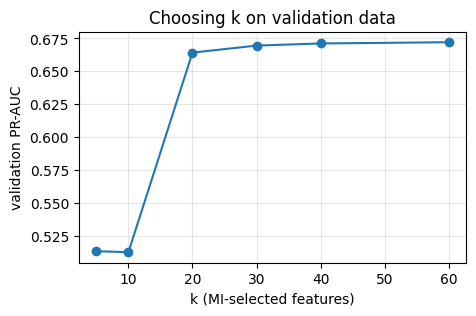

validation PR-AUC by k: {5: np.float64(0.5132), 10: np.float64(0.5124), 20: np.float64(0.6642), 30: np.float64(0.6696), 40: np.float64(0.6712), 60: np.float64(0.6721)}


In [38]:
# MI top-k selection: choose k on a validation split (no peeking at the test set)
tr, te = split_chrono(DF); trn, val = tr[: int(len(tr) * .8)], tr[int(len(tr) * .8):]
ks, f1s = [5, 10, 20, 30, 40, 60], []
for k in ks:
    d = Detector("LightGBM", False, k=k).fit(DF.iloc[trn], DF["y"].values[trn]); f1s.append(binary_metrics(DF["y"].values[val], d.raw_proba(DF.iloc[val]))["pr_auc"])
plt.figure(figsize=(5, 3)); plt.plot(ks, f1s, "o-"); plt.xlabel("k (MI-selected features)"); plt.ylabel("validation PR-AUC"); plt.grid(alpha=.3); plt.title("Choosing k on validation data"); plt.show()
print("validation PR-AUC by k:", dict(zip(ks, np.round(f1s, 4))))

## 3. Multi-class detection, unseen-day generalisation, natural prevalence

,precision,recall,f1-score,support
Benign,0.908,0.847,0.876,8249.000
Bot,0.997,0.943,0.969,1555.000
BruteForce,0.991,0.995,0.993,2326.000
DDoS,1.000,1.000,1.000,1428.000
DoS,0.986,0.942,0.963,224.000
Infiltration,0.327,0.501,0.396,1210.000
accuracy,0.868,0.868,0.868,0.868
macro avg,0.868,0.871,0.866,14992.000
weighted avg,0.893,0.868,0.878,14992.000


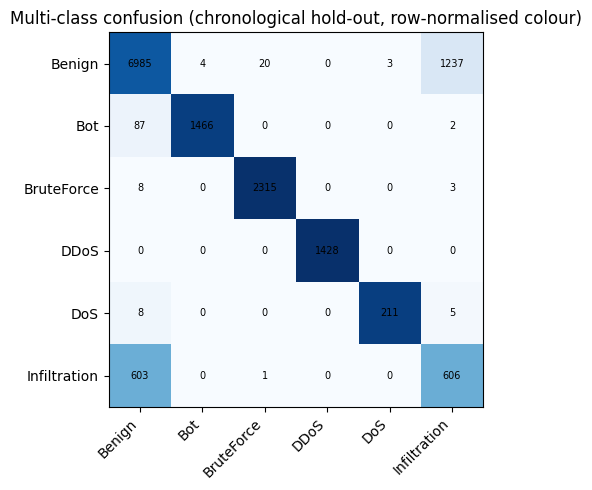

macro-F1 0.866 | MCC 0.803 | balanced-acc 0.871


In [39]:
class FamilyModel:
    """Multi-class attack-family classifier (LightGBM) — also used later to tell the twin WHICH attack is suspected."""
    def __init__(self, use_shortcuts=False, seed=42): self.use_shortcuts, self.seed = use_shortcuts, seed
    def fit(self, df, fam):
        X = make_X(df, self.use_shortcuts); self.input_cols_ = list(X.columns); self.pre = make_preproc("tree", CFG["N_FEATURES"], self.seed)
        Z = self.pre.fit_transform(X, (np.asarray(fam) != "Benign").astype(int)); self.classes_ = sorted(set(fam))
        self.clf = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=63, class_weight="balanced", subsample=0.8, subsample_freq=1,
                                      colsample_bytree=0.8, random_state=self.seed, n_jobs=-1, verbose=-1).fit(Z, np.asarray(fam)); return self
    def proba(self, flows): return self.clf.predict_proba(self.pre.transform(make_X(flows, self.use_shortcuts).reindex(columns=self.input_cols_)))
    def predict_attack_family(self, flows):
        P = pd.DataFrame(self.proba(flows), columns=self.clf.classes_); att = [c for c in P.columns if c != "Benign"]
        return P[att].idxmax(axis=1).values

tr_c, te_c = split_chrono(DF)
fam_model = FamilyModel().fit(DF.iloc[tr_c], DF["Family"].values[tr_c])
pred = fam_model.clf.classes_[fam_model.proba(DF.iloc[te_c]).argmax(1)]; true = DF["Family"].values[te_c]
rep = pd.DataFrame(classification_report(true, pred, output_dict=True, zero_division=0)).T.round(3); RESULTS["multiclass_report_chrono"] = rep
display(rep)
labs = [c for c in fam_model.clf.classes_]; cm = confusion_matrix(true, pred, labels=labs)
plt.figure(figsize=(6, 5)); plt.imshow(cm / cm.sum(1, keepdims=True).clip(1), cmap="Blues"); plt.xticks(range(len(labs)), labs, rotation=45, ha="right"); plt.yticks(range(len(labs)), labs)
for i in range(len(labs)):
    for j in range(len(labs)): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
plt.title("Multi-class confusion (chronological hold-out, row-normalised colour)"); plt.tight_layout(); plt.show()
print("macro-F1 %.3f | MCC %.3f | balanced-acc %.3f" % (f1_score(true, pred, average="macro"), matthews_corrcoef(true, pred), balanced_accuracy_score(true, pred)))

### 3.1 Leave-one-day-out (train on other days, test on an unseen day)
For each held-out day the table says whether its attack families also occur in the training days (**seen family, new day**) or not (**unseen family** = zero-day style). Per-day PR-AUC feeds the Wilcoxon test later.

In [40]:
def lodo(models=("LightGBM", "RandomForest", "LogReg"), use_shortcuts=False):
    rows = []
    for d in DF["Day"].unique():
        tr = np.where(DF["Day"] != d)[0]; te = np.where(DF["Day"] == d)[0]
        fams_te = set(DF["Family"].values[te]) - {"Benign"}; fams_tr = set(DF["Family"].values[tr])
        for m in models:
            _, s, r = fit_eval(DF, tr, te, m, use_shortcuts)
            rows.append(dict(day=d, model=m, test_families="/".join(sorted(fams_te)), family_status="seen elsewhere" if fams_te <= fams_tr else "UNSEEN family",
                             pr_auc=r["pr_auc"], f1=r["f1"], mcc=r["mcc"], recall=r["rec"], fpr=r["fpr"]))
    return pd.DataFrame(rows)

if CFG["RUN_LODO"]:
    lodo_df = lodo(); RESULTS["lodo"] = lodo_df
    display(lodo_df.round(3))
    display(lodo_df.groupby(["model", "family_status"])[["pr_auc", "f1", "mcc", "recall", "fpr"]].agg(["mean", "std"]).round(3))

,day,model,test_families,family_status,pr_auc,f1,mcc,recall,fpr
0,Fri-02,LightGBM,Bot,UNSEEN family,0.525,0.000,-0.182,0.000,0.065
1,Fri-02,RandomForest,Bot,UNSEEN family,0.612,0.050,-0.143,0.028,0.098
2,Fri-02,LogReg,Bot,UNSEEN family,0.568,0.590,0.423,0.451,0.077
3,Wed-14,LightGBM,BruteForce,UNSEEN family,0.879,0.390,0.335,0.247,0.019
4,Wed-14,RandomForest,BruteForce,UNSEEN family,0.850,0.750,0.601,0.638,0.064
5,Wed-14,LogReg,BruteForce,UNSEEN family,0.879,0.861,0.708,0.943,0.248
6,Thu-15,LightGBM,DoS,UNSEEN family,0.722,0.370,0.283,0.236,0.041
7,Thu-15,RandomForest,DoS,UNSEEN family,0.620,0.128,-0.031,0.075,0.092
8,Thu-15,LogReg,DoS,UNSEEN family,0.550,0.442,0.106,0.357,0.259
9,Wed-21,LightGBM,DDoS,UNSEEN family,0.857,0.047,0.098,0.024,0.002


pr_auc            f1           mcc        recall  \
                             mean    std   mean    std   mean    std   mean   
model        family_status                                                    
LightGBM     UNSEEN family  0.722  0.151  0.165  0.197  0.113  0.208  0.103   
LogReg       UNSEEN family  0.585  0.199  0.591  0.190  0.321  0.247  0.601   
RandomForest UNSEEN family  0.682  0.113  0.267  0.309  0.160  0.314  0.199   

                                     fpr         
                              std   mean    std  
model        family_status                       
LightGBM     UNSEEN family  0.127  0.026  0.027  
LogReg       UNSEEN family  0.341  0.323  0.349  
RandomForest UNSEEN family  0.263  0.052  0.047

### 3.2 Same family, NEW day (separating "new attack type" from "new day")
Leave-one-day-out (§3.1) mixes two effects: the family is unseen **and** the day is new. Here the training days already contain the family, and the test day is a *different* day:

| Test day | Family in test | Seen in training on |
|---|---|---|
| Fri-16 | DoS (Hulk / SlowHTTPTest) | Thu-15 (GoldenEye / Slowloris) |
| Thu-01 | Infiltration | Wed-28 |

Same family does **not** mean same tool or same attacker, so a gap to the unseen-family result is an upper bound on what family knowledge alone buys. The two extra CSVs are downloaded here and are not added to `DF`, so later sections are unchanged.


In [41]:
EXTRA_DAYS = {"Fri-16": "Thu-15", "Thu-01": "Wed-28"}        # extra test day -> day that holds the same family in the training data
ALT_BASE = "http://cse-cic-ids2018.s3.amazonaws.com/Processed%20Traffic%20Data%20for%20ML%20Algorithms/"
extra_frames = {}
for day in EXTRA_DAYS:
    p = ensure_day_file(day)
    if p is None:
        p = os.path.join(CFG["DATA_DIR"], DAY_FILES[day])
        try:
            print(f"  downloading {DAY_FILES[day]} (AWS) ..."); urllib.request.urlretrieve(ALT_BASE + DAY_FILES[day], p)
            if os.path.getsize(p) < 1e5: os.remove(p); p = None
        except Exception as e:
            print("   failed:", str(e)[:80]); p = None
    if p is None: print(f"  !! {day} unavailable -> skipped (upload the CSV to {CFG['DATA_DIR']} and re-run)"); continue
    extra_frames[day] = load_day(day, p, CFG["MAX_PER_FAMILY_PER_DAY"], CFG["SEED"])
    print(f"{day}: {len(extra_frames[day]):>7,} rows | " + ", ".join(f"{k}={v}" for k, v in extra_frames[day]["Family"].value_counts().items()))

if extra_frames:
    DF2 = pd.concat([DF] + list(extra_frames.values()), ignore_index=True); DF2["y"] = (DF2["Family"] != "Benign").astype(int)
    tr2 = np.where(DF2["Day"].isin(DF["Day"].unique()))[0]; rows = []
    for d, pair_day in EXTRA_DAYS.items():
        if d not in extra_frames: continue
        te2 = np.where(DF2["Day"] == d)[0]; fams = "/".join(sorted(set(DF2["Family"].values[te2]) - {"Benign"}))
        if DF2["y"].values[te2].sum() == 0: print(f"  !! {d}: no attack rows found, skipped"); continue
        for m in ("LightGBM", "RandomForest", "LogReg"):
            _, s, r = fit_eval(DF2, tr2, te2, m, False)
            rows.append(dict(test_day=d, families=fams, setting="same family, NEW day", model=m, n_attack=int(r["tp"] + r["fn"]),
                             pr_auc=r["pr_auc"], f1=r["f1"], mcc=r["mcc"], recall=r["rec"], fpr=r["fpr"]))
            if "lodo_df" in globals():                                   # the same family, but UNSEEN, from §3.1 (paired day)
                u = lodo_df[(lodo_df["day"] == pair_day) & (lodo_df["model"] == m)]
                if len(u): u = u.iloc[0]; rows.append(dict(test_day=pair_day, families=u["test_families"], setting="family UNSEEN (leave-one-day-out)", model=m,
                                                           n_attack=np.nan, pr_auc=u["pr_auc"], f1=u["f1"], mcc=u["mcc"], recall=u["recall"], fpr=u["fpr"]))
    same_fam_df = pd.DataFrame(rows); RESULTS["same_family_new_day"] = same_fam_df
    display(same_fam_df.sort_values(["families", "model", "setting"]).round(3))
    print("Read: if 'same family, NEW day' is clearly better than 'family UNSEEN', family knowledge transfers across days; if it is still poor, "
          "the detector is tied to the specific tool / attacker / day rather than to the attack family.")
else:
    print("Extra days not available -> same-family test skipped.")


Fri-16:  10,000 rows | Benign=5000, DoS=5000
Thu-01:  10,000 rows | Benign=5000, Infiltration=5000


,test_day,families,setting,model,n_attack,pr_auc,f1,mcc,recall,fpr
1,Thu-15,DoS,family UNSEEN (leave-one-day-out),LightGBM,NaN,0.722,0.370,0.283,0.236,0.041
0,Fri-16,DoS,"same family, NEW day",LightGBM,5000.0,0.993,0.686,0.206,0.995,0.905
5,Thu-15,DoS,family UNSEEN (leave-one-day-out),LogReg,NaN,0.550,0.442,0.106,0.357,0.259
4,Fri-16,DoS,"same family, NEW day",LogReg,5000.0,0.934,0.667,0.034,0.998,0.993
3,Thu-15,DoS,family UNSEEN (leave-one-day-out),RandomForest,NaN,0.620,0.128,-0.031,0.075,0.092
2,Fri-16,DoS,"same family, NEW day",RandomForest,5000.0,0.718,0.579,0.263,0.511,0.255
7,Wed-28,Infiltration,family UNSEEN (leave-one-day-out),LightGBM,NaN,0.626,0.017,0.030,0.008,0.004
6,Thu-01,Infiltration,"same family, NEW day",LightGBM,5000.0,0.550,0.284,0.144,0.179,0.082
11,Wed-28,Infiltration,family UNSEEN (leave-one-day-out),LogReg,NaN,0.604,0.385,0.209,0.263,0.102
10,Thu-01,Infiltration,"same family, NEW day",LogReg,5000.0,0.621,0.483,0.246,0.367,0.151


Read: if 'same family, NEW day' is clearly better than 'family UNSEEN', family knowledge transfers across days; if it is still poor, the detector is tied to the specific tool / attacker / day rather than to the attack family.


### 3.3 Cross-dataset test (CIC-IDS2017) — runs only if a 2017 CSV is supplied
Train on the pooled 2018 days and test on CIC-IDS2017 (e.g. `Wednesday-workingHours.pcap_ISCX.csv` from the *MachineLearningCVE* set, uploaded to Colab). The labels are binary here (attack vs `BENIGN`).

Two variants are reported: **(a)** all 2018 features, with features that have no 2017 counterpart imputed, and **(b)** *common features only* (the 2018 model is trained with the unmapped columns blanked), which is the fairer comparison. Feature definitions can differ between tool versions, so treat this as an indicative robustness test and describe the mapping in the paper. `CIC2017_PATH` below must point to the file; with `None` the cell is skipped.


In [42]:
CIC2017_PATH = None      # e.g. "/content/Wednesday-workingHours.pcap_ISCX.csv"  (or a list of several 2017 CSVs)
MAP2017 = {"Destination Port": "Dst Port", "Flow Duration": "Flow Duration", "Total Fwd Packets": "Tot Fwd Pkts", "Total Backward Packets": "Tot Bwd Pkts",
           "Total Length of Fwd Packets": "TotLen Fwd Pkts", "Total Length of Bwd Packets": "TotLen Bwd Pkts",
           "Fwd Packet Length Max": "Fwd Pkt Len Max", "Fwd Packet Length Min": "Fwd Pkt Len Min", "Fwd Packet Length Mean": "Fwd Pkt Len Mean", "Fwd Packet Length Std": "Fwd Pkt Len Std",
           "Bwd Packet Length Max": "Bwd Pkt Len Max", "Bwd Packet Length Min": "Bwd Pkt Len Min", "Bwd Packet Length Mean": "Bwd Pkt Len Mean", "Bwd Packet Length Std": "Bwd Pkt Len Std",
           "Flow Bytes/s": "Flow Byts/s", "Flow Packets/s": "Flow Pkts/s", "Flow IAT Mean": "Flow IAT Mean", "Flow IAT Std": "Flow IAT Std", "Flow IAT Max": "Flow IAT Max", "Flow IAT Min": "Flow IAT Min",
           "Fwd IAT Total": "Fwd IAT Tot", "Fwd IAT Mean": "Fwd IAT Mean", "Fwd IAT Max": "Fwd IAT Max", "Fwd IAT Min": "Fwd IAT Min",
           "Fwd Packets/s": "Fwd Pkts/s", "Bwd Packets/s": "Bwd Pkts/s", "Packet Length Mean": "Pkt Len Mean", "Packet Length Std": "Pkt Len Std",
           "SYN Flag Count": "SYN Flag Cnt", "ACK Flag Count": "ACK Flag Cnt", "Init_Win_bytes_forward": "Init Fwd Win Byts", "Init_Win_bytes_backward": "Init Bwd Win Byts"}

def load_2017(paths, per_class_cap=60_000, seed=0):
    paths = [paths] if isinstance(paths, (str, os.PathLike)) else list(paths); parts = []
    for p in paths:
        x = pd.read_csv(p, low_memory=False); x.columns = [c.strip() for c in x.columns]
        x = x[x["Label"].astype(str) != "Label"]; parts.append(x)
    x = pd.concat(parts, ignore_index=True); x = x.replace([np.inf, -np.inf], np.nan)
    lab = x["Label"].astype(str).str.strip(); att = lab.str.upper() != "BENIGN"
    keep = pd.concat([x[~att].sample(n=min(int((~att).sum()), per_class_cap), random_state=seed), x[att].sample(n=min(int(att.sum()), per_class_cap), random_state=seed)])
    keep = keep.sort_index(); lab = np.array([str(v).strip() for v in keep["Label"]], dtype=object)
    keep = keep.rename(columns=MAP2017); keep = keep.loc[:, ~keep.columns.duplicated()]
    return keep, np.array([l.upper() != "BENIGN" for l in lab]).astype(int), lab

if CIC2017_PATH:
    x17, y17, lab17 = load_2017(CIC2017_PATH)
    common = [c for c in dict.fromkeys(MAP2017.values()) if c in RAW_COLS and c in x17.columns]
    print(f"2017 test set: {len(x17):,} flows | attack share {y17.mean():.3f} (= PR-AUC of a random scorer) | common features used: {len(common)}/{len(RAW_COLS)}")
    DFc = DF.copy()
    for c in RAW_COLS:
        if c not in common: DFc[c] = np.nan
    x17c = x17.copy()
    for c in RAW_COLS:
        if c not in common and c in x17c.columns: x17c[c] = np.nan
    rows = []; per_label = []
    for tag, train_df, test_df in (("(a) all 2018 features (unmapped imputed)", DF, x17), ("(b) common features only", DFc, x17c)):
        det = Detector("LightGBM", False).fit(train_df, train_df["y"].values); s = det.raw_proba(test_df); r = binary_metrics(y17, s)
        rows.append(dict(variant=tag, pr_auc=r["pr_auc"], roc_auc=r["roc_auc"], f1=r["f1"], mcc=r["mcc"], recall=r["rec"], fpr=r["fpr"]))
        if tag.startswith("(b)"):
            for l in sorted(set(lab17)):
                m_ = lab17 == l; per_label.append(dict(label_2017=l, n=int(m_.sum()), flagged_frac=float((s[m_] >= 0.5).mean())))
    cross_df = pd.DataFrame(rows); RESULTS["cross_dataset_2017"] = cross_df; display(cross_df.round(3))
    pl = pd.DataFrame(per_label); RESULTS["cross_dataset_2017_per_label"] = pl; display(pl.round(3))
    print("flagged_frac = fraction of that 2017 label scored >= 0.5 (recall for attacks; FPR for BENIGN). Report the number of 2017 attack flows and the mapping above.")
else:
    print("CIC2017_PATH not set -> cross-dataset test skipped. Upload a CIC-IDS2017 CSV (MachineLearningCVE) to Colab and set the path above.")


CIC2017_PATH not set -> cross-dataset test skipped. Upload a CIC-IDS2017 CSV (MachineLearningCVE) to Colab and set the path above.


## 4. Natural class imbalance
The training/test samples are capped per family, so they are *not* the real traffic mix. Real networks have attacks at well below 50 %. We therefore re-weight the **test set** to a chosen attack prevalence (by sub-sampling attack rows) and watch precision / PR-AUC / MCC. Also compare imbalance-handling for training: none vs class-weight vs SMOTE.

,attack_prevalence,precision,recall,f1,mcc,pr_auc,roc_auc,fpr,bal_acc
0,0.50,0.9582,0.8561,0.9043,0.8377,0.9648,0.9615,0.0305,0.9128
1,0.20,0.8761,0.8642,0.8701,0.8380,0.9314,0.9626,0.0305,0.9168
2,0.10,0.7546,0.8451,0.7973,0.7749,0.8916,0.9575,0.0305,0.9073
3,0.05,0.5935,0.8479,0.6983,0.6917,0.8670,0.9586,0.0305,0.9087
4,0.01,0.2222,0.8675,0.3538,0.4299,0.8526,0.9688,0.0305,0.9185


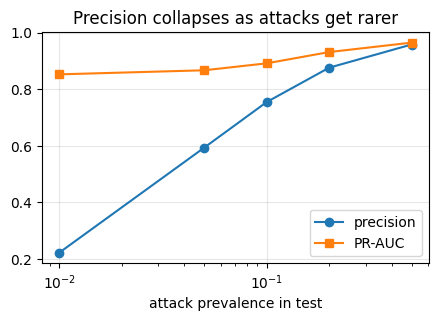

,method,prec,rec,f1,mcc,pr_auc,fpr
0,no weighting,0.7154,0.8341,0.7702,0.7596,0.8645,0.0175
1,class-weight,0.7132,0.8364,0.7699,0.7594,0.8676,0.0177
2,SMOTE (<=40k rows),0.7157,0.8295,0.7684,0.7576,0.8617,0.0173


In [43]:
def at_prevalence(y, s, prev, seed=0):
    rng = np.random.default_rng(seed); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    n_pos = int(round(prev * len(neg) / (1 - prev))); n_pos = min(n_pos, len(pos)); idx = np.r_[neg, rng.choice(pos, n_pos, replace=False)]
    return y[idx], s[idx]

tr, te = split_chrono(DF); det_nat, s_nat, _ = fit_eval(DF, tr, te, "LightGBM", False); y_te = DF["y"].values[te]
rows = []
for prev in (0.5, 0.2, 0.1, 0.05, 0.01):
    m = binary_metrics(*at_prevalence(y_te, s_nat, prev)); rows.append(dict(attack_prevalence=prev, precision=m["prec"], recall=m["rec"], f1=m["f1"], mcc=m["mcc"], pr_auc=m["pr_auc"], roc_auc=m["roc_auc"], fpr=m["fpr"], bal_acc=m["bal_acc"]))
prev_df = pd.DataFrame(rows); RESULTS["prevalence_sweep"] = prev_df; display(prev_df.round(4))
plt.figure(figsize=(5, 3)); plt.plot(prev_df.attack_prevalence, prev_df.precision, "o-", label="precision"); plt.plot(prev_df.attack_prevalence, prev_df.pr_auc, "s-", label="PR-AUC"); plt.xscale("log"); plt.legend(); plt.xlabel("attack prevalence in test"); plt.grid(alpha=.3); plt.title("Precision collapses as attacks get rarer"); plt.show()

# training-time imbalance handling (evaluated at 5 % prevalence)
from imblearn.over_sampling import SMOTE
Xtr = make_X(DF.iloc[tr], False); pre = make_preproc("tree", CFG["N_FEATURES"]); Ztr = pre.fit_transform(Xtr, DF["y"].values[tr]); Zte = pre.transform(make_X(DF.iloc[te], False))
cands = {"no weighting": lgb.LGBMClassifier(n_estimators=150, random_state=42, verbose=-1, n_jobs=-1), "class-weight": lgb.LGBMClassifier(n_estimators=150, class_weight="balanced", random_state=42, verbose=-1, n_jobs=-1)}
imb = []
for nm, mdl in cands.items():
    mdl.fit(Ztr, DF["y"].values[tr]); m = binary_metrics(*at_prevalence(y_te, mdl.predict_proba(Zte)[:, 1], 0.05)); imb.append(dict(method=nm, **{k: m[k] for k in ("prec", "rec", "f1", "mcc", "pr_auc", "fpr")}))
sm_idx = np.random.default_rng(0).choice(len(Ztr), min(len(Ztr), 40000), replace=False)
Zs, ys = SMOTE(random_state=42).fit_resample(Ztr[sm_idx], DF["y"].values[tr][sm_idx])
mdl = lgb.LGBMClassifier(n_estimators=150, random_state=42, verbose=-1, n_jobs=-1).fit(Zs, ys); m = binary_metrics(*at_prevalence(y_te, mdl.predict_proba(Zte)[:, 1], 0.05))
imb.append(dict(method="SMOTE (<=40k rows)", **{k: m[k] for k in ("prec", "rec", "f1", "mcc", "pr_auc", "fpr")}))
imb_df = pd.DataFrame(imb); RESULTS["imbalance_handling"] = imb_df; display(imb_df.round(4))

## 5. Baselines, statistics and runtime
Supervised: LogReg, Decision Tree, Random Forest, XGBoost, LightGBM, Linear-SVM, MLP. Anomaly baselines (benign-only training): Isolation Forest, MLP auto-encoder. Sequence models (GRU etc.) are in §9. All use the chronological split, no shortcut features, 95 % bootstrap CIs, McNemar vs the best model.

In [44]:
from statsmodels.stats.contingency_tables import mcnemar
from scipy.stats import wilcoxon
tr, te = split_chrono(DF); y_tr, y_te = DF["y"].values[tr], DF["y"].values[te]
base_rows, base_scores, base_models = [], {}, {}
for name in ["LogReg", "DecisionTree", "RandomForest", "XGBoost", "LightGBM", "LinearSVM", "MLP", "IsolationForest", "Autoencoder"]:
    det = (AnomalyDetector("IsolationForest" if name == "IsolationForest" else "Autoencoder") if name in ("IsolationForest", "Autoencoder") else Detector(name, False)).fit(DF.iloc[tr], y_tr)
    t = time.perf_counter(); s = det.raw_proba(DF.iloc[te]); lat = (time.perf_counter() - t) / len(te) * 1e3
    thr = 0.5 if name not in ("IsolationForest", "Autoencoder") else np.percentile(s[y_te == 0], 95)       # anomaly thr: 5 % FPR on benign test (generous to the baseline)
    m = binary_metrics(y_te, s, thr); lo, hi = bootstrap_ci(y_te, s, "pr_auc", thr=thr)
    base_rows.append(dict(model=name, pr_auc=m["pr_auc"], pr_auc_ci=f"[{lo:.3f},{hi:.3f}]", roc_auc=m["roc_auc"], f1=m["f1"], mcc=m["mcc"], prec=m["prec"], rec=m["rec"], fpr=m["fpr"], fnr=m["fnr"],
                          train_s=det.fit_seconds_, ms_per_flow=lat))
    base_scores[name] = (s >= thr).astype(int); base_models[name] = det
base_df = pd.DataFrame(base_rows).sort_values("pr_auc", ascending=False).reset_index(drop=True); best = base_df.model[0]
mc = []
for n, p in base_scores.items():
    if n == best: continue
    b01 = int(((base_scores[best] == y_te) & (p != y_te)).sum()); b10 = int(((base_scores[best] != y_te) & (p == y_te)).sum())
    mc.append(dict(model=n, best_right_other_wrong=b01, best_wrong_other_right=b10, mcnemar_p=mcnemar([[0, b01], [b10, 0]], exact=(b01 + b10) < 50).pvalue))
base_df = base_df.merge(pd.DataFrame(mc), on="model", how="left"); RESULTS["baselines"] = base_df; display(base_df.round(4))
print("Best by PR-AUC:", best, "| McNemar p<0.05 => the error patterns differ significantly from the best model.")

# repeated seeds (model randomness) for the tree models
seed_rows = []
for sd in range(CFG["N_SEEDS"]):
    for name in ("RandomForest", "XGBoost", "LightGBM"):
        _, _, m = fit_eval(DF, tr, te, name, False, seed=CFG["SEED"] + sd); seed_rows.append(dict(model=name, seed=sd, pr_auc=m["pr_auc"], f1=m["f1"], mcc=m["mcc"]))
seed_df = pd.DataFrame(seed_rows); RESULTS["seed_runs"] = seed_df; display(seed_df.groupby("model")[["pr_auc", "f1", "mcc"]].agg(["mean", "std"]).round(4))
if CFG["RUN_LODO"] and DF["Day"].nunique() >= 6:
    piv = lodo_df.pivot(index="day", columns="model", values="pr_auc")
    for a, b in (("LightGBM", "RandomForest"), ("LightGBM", "LogReg")):
        if a in piv and b in piv: print(f"Wilcoxon over {len(piv)} held-out days, PR-AUC {a} vs {b}: p = {wilcoxon(piv[a], piv[b]).pvalue:.4f}")

,model,pr_auc,pr_auc_ci,roc_auc,f1,mcc,prec,rec,fpr,fnr,train_s,ms_per_flow,best_right_other_wrong,best_wrong_other_right,mcnemar_p
0,LightGBM,0.9648,"[0.962,0.967]",0.9615,0.9043,0.8377,0.9582,0.8561,0.0305,0.1439,11.9247,0.0150,NaN,NaN,NaN
1,XGBoost,0.9630,"[0.960,0.965]",0.9583,0.9056,0.8410,0.9635,0.8542,0.0264,0.1458,14.1195,0.0092,77.0,98.0,0.1306
2,RandomForest,0.9592,"[0.956,0.962]",0.9540,0.8895,0.8054,0.9185,0.8622,0.0626,0.1378,20.6297,0.0259,391.0,168.0,0.0000
3,MLP,0.9522,"[0.947,0.956]",0.9450,0.9060,0.8450,0.9757,0.8456,0.0172,0.1544,22.3004,0.0116,147.0,186.0,0.0373
4,DecisionTree,0.9121,"[0.905,0.920]",0.9310,0.8974,0.8246,0.9470,0.8527,0.0390,0.1473,10.7222,0.0041,246.0,153.0,0.0000
5,LinearSVM,0.8645,"[0.854,0.874]",0.8988,0.8455,0.7155,0.8308,0.8607,0.1433,0.1393,14.9890,0.0084,1129.0,230.0,0.0000
6,LogReg,0.8639,"[0.854,0.873]",0.8975,0.8482,0.7218,0.8388,0.8579,0.1348,0.1421,14.7847,0.0089,1073.0,225.0,0.0000
7,Autoencoder,0.6961,"[0.684,0.709]",0.7494,0.3593,0.2679,0.7914,0.2324,0.0501,0.7676,12.9083,0.0111,4729.0,362.0,0.0000
8,IsolationForest,0.6025,"[0.590,0.616]",0.6928,0.0745,-0.0213,0.4014,0.0411,0.0501,0.9589,2.9694,0.0208,5965.0,308.0,0.0000


Best by PR-AUC: LightGBM | McNemar p<0.05 => the error patterns differ significantly from the best model.


pr_auc              f1             mcc        
                mean     std    mean     std    mean     std
model                                                       
LightGBM      0.9642  0.0007  0.9038  0.0004  0.8368  0.0009
RandomForest  0.9599  0.0006  0.8886  0.0008  0.8037  0.0016
XGBoost       0.9636  0.0005  0.9058  0.0005  0.8416  0.0009

## 6. Primary detector, calibration and cost-based thresholds
The legacy pipeline used `risk = P(Bot)*100` with fixed 30/70 cut-offs. Raw forest/boosting scores are not probabilities. Here: fit on the early part of the training period, **calibrate on a later validation slice** (isotonic / Platt), report Brier + ECE + reliability curve, and choose the alert threshold from an explicit **cost model** instead of 30/70.

Primary detector (best tree model by PR-AUC): LightGBM


,version,brier,ece,pr_auc
0,raw,0.0801,0.0558,0.9566
1,isotonic,0.0748,0.0260,0.9516
2,platt,0.0791,0.0505,0.9566


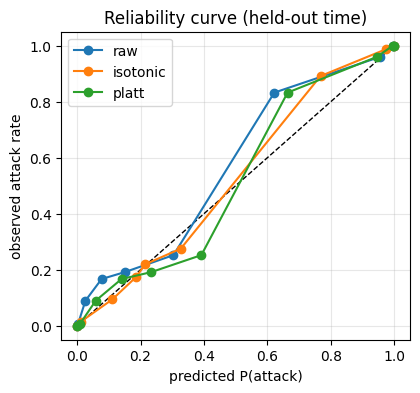

,threshold,value,precision,recall,fpr,mcc
0,fixed 'block' threshold 0.70,0.70,0.6485,0.8203,0.0234,0.7135
1,fixed 'alert' threshold 0.30,0.30,0.3442,0.8548,0.0857,0.5083
2,"cost-based (FN=10x FP, 5% prevalence)",0.44,0.6461,0.8203,0.0236,0.7121


Thresholds are an operating-cost decision (here c_fn = 10 × c_fp and 5 % attack prevalence).


In [45]:
from sklearn.calibration import calibration_curve
tree_best = base_df[base_df.model.isin(["RandomForest", "XGBoost", "LightGBM"])].model.iloc[0]
PRIMARY = tree_best; print("Primary detector (best tree model by PR-AUC):", PRIMARY)
sub = DF.iloc[tr].reset_index(drop=True); a_idx, v_idx = split_chrono(sub, frac=0.2, gap=CFG["GAP_SECONDS"])
primary = Detector(PRIMARY, False).fit(sub.iloc[a_idx], sub["y"].values[a_idx])
yv, yt = sub["y"].values[v_idx], DF["y"].values[te]; TE = DF.iloc[te].reset_index(drop=True)
raw_v, raw_t = primary.raw_proba(sub.iloc[v_idx]), primary.raw_proba(TE)
primary.calibrate(sub.iloc[v_idx], yv, "isotonic"); iso_t = primary.proba(TE)
plat = Detector.calibrate(primary, sub.iloc[v_idx], yv, "platt"); plat_t = primary.proba(TE); primary.calibrate(sub.iloc[v_idx], yv, "isotonic")   # keep isotonic as final
cal_tab = pd.DataFrame([dict(version=n, brier=brier_score_loss(yt, p), ece=ece(yt, p), pr_auc=binary_metrics(yt, p)["pr_auc"]) for n, p in (("raw", raw_t), ("isotonic", iso_t), ("platt", plat_t))])
RESULTS["calibration"] = cal_tab; display(cal_tab.round(4))
plt.figure(figsize=(4.5, 4)); plt.plot([0, 1], [0, 1], "k--", lw=1)
for n, p in (("raw", raw_t), ("isotonic", iso_t), ("platt", plat_t)):
    f, m = calibration_curve(yt, p, n_bins=10, strategy="quantile"); plt.plot(m, f, "o-", label=n)
plt.xlabel("predicted P(attack)"); plt.ylabel("observed attack rate"); plt.legend(); plt.title("Reliability curve (held-out time)"); plt.grid(alpha=.3); plt.show()

def choose_threshold(y, p, c_fn=10.0, c_fp=1.0, prev=0.05):
    w1, w0 = prev / max(y.mean(), 1e-9), (1 - prev) / max(1 - y.mean(), 1e-9); best = (None, 1e18)
    for t in np.linspace(0.02, 0.98, 49):
        pr = p >= t; cost = c_fn * w1 * ((~pr) & (y == 1)).sum() + c_fp * w0 * (pr & (y == 0)).sum()
        if cost < best[1]: best = (t, cost)
    return best[0]
PRIOR = 0.05
THR_COST = choose_threshold(yv, primary.proba(sub.iloc[v_idx]), c_fn=10, c_fp=1, prev=PRIOR)
rows = []
for nm, thr in (("fixed 'block' threshold 0.70", 0.70), ("fixed 'alert' threshold 0.30", 0.30), ("cost-based (FN=10x FP, 5% prevalence)", THR_COST)):
    m = binary_metrics(*at_prevalence(yt, iso_t, PRIOR), thr=thr); rows.append(dict(threshold=nm, value=round(thr, 2), precision=m["prec"], recall=m["rec"], fpr=m["fpr"], mcc=m["mcc"]))
thr_tab = pd.DataFrame(rows); RESULTS["threshold_choice"] = thr_tab; display(thr_tab.round(4))
print("Thresholds are an operating-cost decision (here c_fn = 10 × c_fp and 5 % attack prevalence).")

## 7. Explainable AI — SHAP, LIME, permutation importance

,feature,mean|SHAP|,what it tells the analyst
33,Init Fwd Win Byts,1.3348,TCP window (OS / tool fingerprint)
35,Fwd Seg Size Min,1.2236,general flow statistic
18,Fwd IAT Min,0.6868,"timing regularity / inter-arrival (beaconing, ..."
5,Fwd Pkt Len Std,0.4291,packet-size profile (payload type / tool finge...
34,Init Bwd Win Byts,0.3346,TCP window (OS / tool fingerprint)
14,Flow IAT Min,0.3288,"timing regularity / inter-arrival (beaconing, ..."
20,Fwd Header Len,0.3207,general flow statistic
22,Fwd Pkts/s,0.2423,packet rate (flooding / scanning)
4,Fwd Pkt Len Mean,0.2152,packet-size profile (payload type / tool finge...
0,Flow Duration,0.1976,flow duration (slow or long-lived sessions)


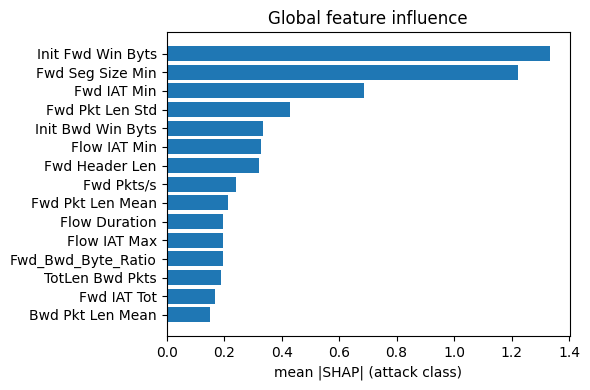

,feature,perm_importance
33,Init Fwd Win Byts,0.1030
35,Fwd Seg Size Min,0.0375
10,Flow Pkts/s,0.0108
18,Fwd IAT Min,0.0104
14,Flow IAT Min,0.0056
23,Bwd Pkts/s,0.0032
15,Fwd IAT Tot,0.0028
0,Flow Duration,0.0022


Spearman(SHAP, permutation): 0.556
Flow #0: true=ATTACK (Bot) | calibrated P(attack)=1.000 -> risk=100.0
   + Fwd Pkt Len Mean       SHAP=+0.973  | packet-size profile (payload type / tool fingerprint)
   + Fwd IAT Min            SHAP=+0.660  | timing regularity / inter-arrival (beaconing, slow-DoS)
   + Fwd Pkt Len Std        SHAP=+0.555  | packet-size profile (payload type / tool fingerprint)
   + Fwd_Bwd_Byte_Ratio     SHAP=+0.517  | request/response asymmetry
   - Init Fwd Win Byts      SHAP=-0.514  | TCP window (OS / tool fingerprint)
   LIME top: [('35.00 < Fwd IAT Min <= 485.75', 0.119), ('247.50 < Flow IAT Mean <= 1805.50', 0.077), ('Fwd Pkt Len Mean > 105.44', 0.067), ('768.00 < Pkt Len Var <= 42968.42', 0.056), ('Flow IAT Min <= 4.00', 0.055)]

-- a FALSE POSITIVE --
Flow #147: true=benign | calibrated P(attack)=0.704 -> risk=70.4
   - Init Fwd Win Byts      SHAP=-0.908  | TCP window (OS / tool fingerprint)
   - Fwd Seg Size Min       SHAP=-0.760  | general flow statistic
   

In [46]:
import shap
from sklearn.inspection import permutation_importance
BEHAVIOUR = [("IAT", "timing regularity / inter-arrival (beaconing, slow-DoS)"), ("Pkts/s", "packet rate (flooding / scanning)"), ("Byts/s", "byte rate (volumetric)"),
             ("Pkt Len", "packet-size profile (payload type / tool fingerprint)"), ("Flag", "TCP-flag behaviour (SYN floods, scans)"), ("Win Byts", "TCP window (OS / tool fingerprint)"),
             ("Duration", "flow duration (slow or long-lived sessions)"), ("Ratio", "request/response asymmetry"), ("Tot", "traffic volume"), ("Total", "traffic volume"),
             ("Dst Port", "targeted service"), ("Proto", "protocol"), ("Mean_Pkt", "average packet size")]
def behaviour(f): return next((d for k, d in BEHAVIOUR if k.lower() in f.lower()), "general flow statistic")

def shap_attack(model, Z):
    """SHAP values for the 'attack' class as (n_samples, n_features), robust to shap/sklearn version differences."""
    sv = shap.TreeExplainer(model).shap_values(Z)
    if isinstance(sv, list): sv = sv[1] if len(sv) > 1 else sv[0]
    sv = np.asarray(sv); return sv[:, :, 1] if sv.ndim == 3 else sv

fn = primary.feature_names_; Zte = primary.Z(TE); n_ex = min(400, len(Zte)); ex_idx = np.random.default_rng(0).choice(len(Zte), n_ex, replace=False)
sv = shap_attack(primary.clf, Zte[ex_idx]); imp = pd.DataFrame({"feature": fn, "mean|SHAP|": np.abs(sv).mean(0)}).sort_values("mean|SHAP|", ascending=False)
imp["what it tells the analyst"] = imp.feature.map(behaviour); RESULTS["shap_global"] = imp; display(imp.head(12).round(4))
top = imp.head(15).iloc[::-1]; plt.figure(figsize=(6, 4)); plt.barh(top.feature, top["mean|SHAP|"]); plt.xlabel("mean |SHAP| (attack class)"); plt.title("Global feature influence"); plt.tight_layout(); plt.show()

pi = permutation_importance(primary.clf, Zte[ex_idx], yt[ex_idx], n_repeats=3, random_state=0, scoring="average_precision")
perm = pd.DataFrame({"feature": fn, "perm_importance": pi.importances_mean}).sort_values("perm_importance", ascending=False); display(perm.head(8).round(4))
print("Spearman(SHAP, permutation):", round(imp.set_index("feature")["mean|SHAP|"].rank().corr(perm.set_index("feature")["perm_importance"].rank()), 3))

def explain_flow(i, topn=5):
    """Per-flow explanation: calibrated risk + SHAP drivers + LIME cross-check."""
    z = Zte[i:i + 1]; s = shap_attack(primary.clf, z)[0]; p = float(primary.proba(TE.iloc[[i]])[0])
    order = np.argsort(-np.abs(s))[:topn]
    print(f"Flow #{i}: true={'ATTACK ('+TE.Family[i]+')' if yt[i] else 'benign'} | calibrated P(attack)={p:.3f} -> risk={100*p:.1f}")
    for j in order: print(f"   {'+' if s[j] > 0 else '-'} {fn[j]:<22} SHAP={s[j]:+.3f}  | {behaviour(fn[j])}")
    from lime.lime_tabular import LimeTabularExplainer
    lt = LimeTabularExplainer(Zte[ex_idx], feature_names=fn, class_names=["benign", "attack"], mode="classification", random_state=0)
    le = lt.explain_instance(Zte[i], primary.clf.predict_proba, num_features=topn, num_samples=800)
    print("   LIME top:", [(f, round(w, 3)) for f, w in le.as_list()]); return s
tp = np.where((yt == 1) & (iso_t > .5))[0]; fp_ = np.where((yt == 0) & (iso_t > .5))[0]
if len(tp): explain_flow(int(tp[0]))
if len(fp_): print("\n-- a FALSE POSITIVE --"); explain_flow(int(fp_[0]))

## 8. Temporal attack prediction
Flow-level classification alone does not forecast: a legacy approach classified single flows and then "forecast" a linear fit on five identical scores. Here we build **time-window sequences** from a time-ordered day and forecast whether the *next* windows will contain attack traffic.
Detector scores for the stream are **cross-fitted in contiguous time blocks** (each block scored by a model that never saw it). Forecasters are trained on early windows and tested on later ones.
Baselines: persistence, EWMA, logistic regression; models: LightGBM / MLP on lag features, optional GRU (PyTorch). Reported: precision/recall/F1/PR-AUC, MAE/RMSE of the attack-ratio, and **early-warning lead time** at attack onsets.

Stream Fri-02: 104,858 flows, attack share 0.275, 2018-03-02 08:46:35 -> 2018-03-02 17:30:15
windows: 524 | windows with >=20% attack flows: 296
train windows 310 (attack-next=190) | test windows 207 (attack-next=106)


,model,prec,rec,f1,mcc,pr_auc
0,Persistence,0.935,0.953,0.944,0.884,0.915
1,EWMA(0.5),0.930,1.000,0.964,0.925,0.930
2,LogReg(lags),0.914,1.000,0.955,0.907,0.910
3,LightGBM(lags),0.912,0.981,0.945,0.886,0.921
4,MLP(lags),0.914,1.000,0.955,0.907,0.945
5,GRU(lags),0.922,1.000,0.959,0.916,0.935


,model,MAE,RMSE
0,Persistence,0.0652,0.1167
1,EWMA(0.5),0.0624,0.1098
2,Ridge(lags),0.0615,0.1085
3,LightGBM(lags),0.0706,0.1187


Early-warning lead time (positive = warned BEFORE the attack onset; negative = detected late; first alarm within [-H, +H] windows of the onset; earlier alarms are treated as false alarms and ignored):


""


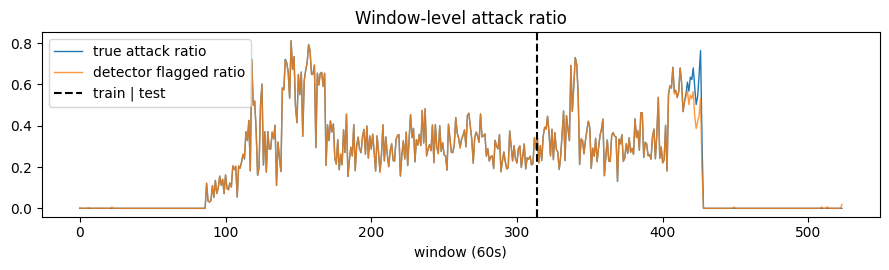

Caveat: a day with two attack bursts gives very few onsets. Lead time could not be evaluated reliably.


In [47]:
from sklearn.linear_model import Ridge
WIN = 60                                   # window length in seconds
H = 3                                      # forecast horizon (windows)
LAGS = 5
stream_day = "Fri-02" if "Fri-02" in CFG["DAYS"] else DF.loc[DF.Family != "Benign", "Day"].iloc[0]
sp = ensure_day_file(stream_day)
stream = load_day(stream_day, sp, 10 ** 9, CFG["SEED"], keep_all_fraction=CFG["STREAM_FRAC"]).dropna(subset=["ts"]).reset_index(drop=True)
stream["y"] = (stream["Family"] != "Benign").astype(int); print(f"Stream {stream_day}: {len(stream):,} flows, attack share {stream.y.mean():.3f}, {stream.ts.min()} -> {stream.ts.max()}")

# cross-fitted detector scores over contiguous blocks (purge 2 windows around each block)
K = 6; edges = np.linspace(0, len(stream), K + 1).astype(int); stream["score"] = 0.0
for b in range(K):
    te_i = np.arange(edges[b], edges[b + 1]); t0, t1 = stream.ts[te_i[0]] - pd.Timedelta(seconds=2 * WIN), stream.ts[te_i[-1]] + pd.Timedelta(seconds=2 * WIN)
    tr_i = np.where((stream.ts < t0) | (stream.ts > t1))[0]
    if len(np.unique(stream.y[tr_i])) < 2: stream.loc[te_i, "score"] = 0.5; continue
    tr_i = np.random.default_rng(b).choice(tr_i, min(len(tr_i), 60000), replace=False)
    d = Detector("LightGBM", False).fit(stream.iloc[tr_i], stream.y.values[tr_i]); stream.loc[te_i, "score"] = d.raw_proba(stream.iloc[te_i])

stream["win"] = ((stream.ts - stream.ts.min()).dt.total_seconds() // WIN).astype(int)
g = stream.groupby("win"); W = pd.DataFrame({"n": g.size(), "mean_s": g.score.mean(), "max_s": g.score.max(), "std_s": g.score.std().fillna(0),
                                            "frac_flag": g.score.apply(lambda s: (s > .5).mean()), "a_true": g.y.mean()}).reindex(range(stream.win.max() + 1)).fillna(0)
W["log_n"] = np.log1p(W.n); feat_cols = ["log_n", "mean_s", "max_s", "std_s", "frac_flag"]
print("windows:", len(W), "| windows with >=20% attack flows:", int((W.a_true >= .2).sum()))

def lag_matrix(W, lags, h):
    F = np.hstack([W[feat_cols].shift(l).values for l in range(lags)]); T = len(W)
    idx = np.arange(lags - 1, T - h); return F[idx], idx
Xl, idx = lag_matrix(W, LAGS, H); y_cls = (W.a_true.values[idx + H] >= .2).astype(int); y_reg = W.a_true.values[idx + H]
split = int(len(idx) * .6)
if y_cls[split:].sum() == 0 or y_cls[:split].sum() == 0: split = int(len(idx) * .5)
Xa, Xb, ya, yb, ra, rb = Xl[:split], Xl[split:], y_cls[:split], y_cls[split:], y_reg[:split], y_reg[split:]
print(f"train windows {len(Xa)} (attack-next={ya.sum()}) | test windows {len(Xb)} (attack-next={yb.sum()})")

cur_flag = W.frac_flag.values[idx][split:]; ewma = pd.Series(W.frac_flag.values).ewm(alpha=.5).mean().values[idx][split:]
preds = {"Persistence": (cur_flag >= .2).astype(float), "EWMA(0.5)": (ewma >= .2).astype(float)}
regs = {"Persistence": cur_flag, "EWMA(0.5)": ewma}
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(Xa); Xa_s, Xb_s = sc.transform(Xa), sc.transform(Xb)
if ya.min() != ya.max():
    preds["LogReg(lags)"] = LogisticRegression(max_iter=500, class_weight="balanced").fit(Xa_s, ya).predict_proba(Xb_s)[:, 1]
    preds["LightGBM(lags)"] = lgb.LGBMClassifier(n_estimators=150, learning_rate=.05, num_leaves=15, class_weight="balanced", verbose=-1, random_state=42).fit(Xa, ya).predict_proba(Xb)[:, 1]
    preds["MLP(lags)"] = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=300, random_state=42).fit(Xa_s, ya).predict_proba(Xb_s)[:, 1]
regs["Ridge(lags)"] = np.clip(Ridge(alpha=1.0).fit(Xa_s, ra).predict(Xb_s), 0, 1)
regs["LightGBM(lags)"] = np.clip(lgb.LGBMRegressor(n_estimators=150, learning_rate=.05, num_leaves=15, verbose=-1, random_state=42).fit(Xa, ra).predict(Xb), 0, 1)

# ---- optional GRU (PyTorch). Wrapped in try/except so the notebook still runs if PyTorch is unavailable. ----
try:
    import torch, torch.nn as nn
    torch.manual_seed(42); nf = len(feat_cols)
    class GRUNet(nn.Module):
        def __init__(s): super().__init__(); s.g = nn.GRU(nf, 32, batch_first=True); s.o = nn.Linear(32, 1)
        def forward(s, x): h, _ = s.g(x); return s.o(h[:, -1]).squeeze(-1)
    def seq(X): return torch.tensor(sc.transform(X).reshape(len(X), LAGS, nf)[:, ::-1].copy(), dtype=torch.float32)   # oldest -> newest
    net = GRUNet(); opt = torch.optim.Adam(net.parameters(), 1e-2); pw = torch.tensor(max((1 - ya.mean()) / max(ya.mean(), 1e-3), 1.0))
    xa_t, ya_t = seq(Xa), torch.tensor(ya, dtype=torch.float32)
    for ep in range(60):
        opt.zero_grad(); loss = nn.functional.binary_cross_entropy_with_logits(net(xa_t), ya_t, pos_weight=pw); loss.backward(); opt.step()
    preds["GRU(lags)"] = torch.sigmoid(net(seq(Xb))).detach().numpy()
except Exception as e: print("GRU skipped:", str(e)[:80])

rows = []
for n, p in preds.items():
    m = binary_metrics(yb, np.asarray(p, float)); rows.append(dict(model=n, prec=m["prec"], rec=m["rec"], f1=m["f1"], mcc=m["mcc"], pr_auc=m["pr_auc"]))
cls_tab = pd.DataFrame(rows); RESULTS["temporal_classification"] = cls_tab; display(cls_tab.round(3))
reg_tab = pd.DataFrame([dict(model=n, MAE=np.abs(p - rb).mean(), RMSE=np.sqrt(((p - rb) ** 2).mean())) for n, p in regs.items()]); RESULTS["temporal_regression"] = reg_tab; display(reg_tab.round(4))

# ---- early-warning lead time at attack onsets (test region) ----
a = W.a_true.values; onset = [t for t in range(10, len(a)) if a[t] >= .2 and a[t - 1] < .2 and a[t - 5:t].max() < .2]
rows = []
for n, p in preds.items():
    alarm = {int(idx[split:][i]): int(np.asarray(p)[i] >= .5) for i in range(len(Xb))}; leads = []
    for t0 in onset:
        if t0 not in alarm and (t0 - 10) < idx[split]: continue
        cand = [t for t in range(t0 - H, t0 + H + 1) if alarm.get(t, 0)]; leads.append((t0 - cand[0]) * WIN if cand else np.nan)
    if leads: rows.append(dict(model=n, onsets=len(leads), missed=int(np.isnan(leads).sum()), median_lead_s=np.nanmedian(leads) if not np.all(np.isnan(leads)) else np.nan))
lead_tab = pd.DataFrame(rows); RESULTS["early_warning"] = lead_tab
print("Early-warning lead time (positive = warned BEFORE the attack onset; negative = detected late; first alarm within [-H, +H] windows of the onset; earlier alarms are treated as false alarms and ignored):"); display(lead_tab)
fig, ax = plt.subplots(figsize=(9, 2.8)); ax.plot(W.a_true.values, label="true attack ratio", lw=1); ax.plot(W.frac_flag.values, label="detector flagged ratio", lw=1, alpha=.8)
ax.axvline(idx[split], color="k", ls="--", label="train | test"); ax.legend(); ax.set_xlabel(f"window ({WIN}s)"); plt.title("Window-level attack ratio"); plt.tight_layout(); plt.show()
print("Caveat: a day with two attack bursts gives very few onsets. Lead time could not be evaluated reliably.")

## 9. Realistic topology, principled risk propagation, multi-factor risk
Legacy: a 5-node chain with `Users` after `Database` and a fixed 0.70 decay per hop.
Here: a 14-node enterprise network (Internet → perimeter firewall → DMZ → internal LAN, plus a VPN path and an IoT segment) with **multiple paths**.
Each edge carries an *exploit probability* `p = reach × CVSS(target)/10` and an ATT&CK technique tag; risk spreads by a **Monte-Carlo independent-cascade (Bayesian attack-graph style)** model, and a **sensitivity analysis** replaces the arbitrary 0.70.

⚠ The CVSS-like scores, criticalities and `reach` values below are **illustrative assumptions**. They are not measurements; replacing them with values from a real vulnerability scan (NVD/CVSS exploitability) and a documented asset inventory is future work, and the ATT&CK technique IDs are an approximate mapping.

Digital-twin graph: 14 nodes, 18 edges, DAG=True


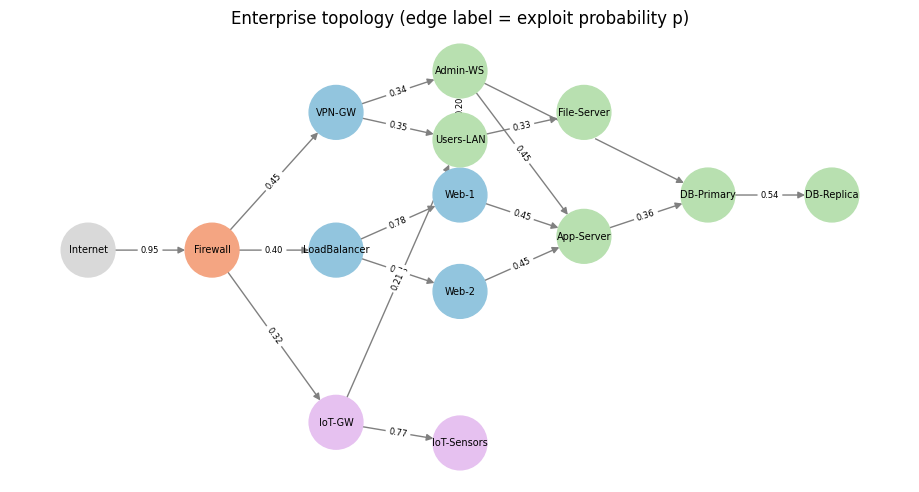

legacy chain risk (Internet->Firewall->Web->DB->Users, fixed 0.70): [100.0, 70.0, 49.0, 34.3, 24.0]


,node,zone,crit,P(compromised | Internet attacker)
0,Internet,external,0.0,1.000
1,Firewall,perimeter,0.0,0.949
2,VPN-GW,dmz,3.0,0.430
3,LoadBalancer,dmz,3.0,0.370
12,IoT-GW,iot,2.0,0.294
4,Web-1,dmz,4.0,0.281
5,Web-2,dmz,4.0,0.279
6,App-Server,internal,4.0,0.279
13,IoT-Sensors,iot,1.0,0.222
11,Users-LAN,internal,2.0,0.206


In [48]:
import networkx as nx
from scipy.stats import spearmanr
#            zone        crit(1-5)  cvss(0-10, illustrative)
# Firewall = policy-enforcement point: cvss=10 / crit=0 means 'traffic is forwarded' (p~0.95); compromise of the firewall itself is not modelled.
NODES = {"Internet": ("external", 0, 0.0), "Firewall": ("perimeter", 0, 10.0), "VPN-GW": ("dmz", 3, 7.5), "LoadBalancer": ("dmz", 3, 5.0),
         "Web-1": ("dmz", 4, 7.8), "Web-2": ("dmz", 4, 7.8), "App-Server": ("internal", 4, 6.5), "DB-Primary": ("internal", 5, 6.0),
         "DB-Replica": ("internal", 4, 6.0), "File-Server": ("internal", 3, 5.5), "Admin-WS": ("internal", 4, 6.8), "Users-LAN": ("internal", 2, 7.0),
         "IoT-GW": ("iot", 2, 8.0), "IoT-Sensors": ("iot", 1, 8.5)}
#          src            dst            reach  ATT&CK technique (approximate mapping — verify against the ATT&CK matrix)
EDGES = [("Internet", "Firewall", 1.0, "T1190 Exploit Public-Facing App"), ("Firewall", "LoadBalancer", 0.8, "T1190 Exploit Public-Facing App"),
         ("Firewall", "VPN-GW", 0.6, "T1133 External Remote Services"), ("Firewall", "IoT-GW", 0.4, "T1190 Exploit Public-Facing App"),
         ("LoadBalancer", "Web-1", 1.0, "T1190 Exploit Public-Facing App"), ("LoadBalancer", "Web-2", 1.0, "T1190 Exploit Public-Facing App"),
         ("Web-1", "App-Server", 0.7, "T1210 Exploitation of Remote Services"), ("Web-2", "App-Server", 0.7, "T1210 Exploitation of Remote Services"),
         ("App-Server", "DB-Primary", 0.6, "T1210 Exploitation of Remote Services"), ("DB-Primary", "DB-Replica", 0.9, "T1021 Remote Services"),
         ("VPN-GW", "Admin-WS", 0.5, "T1078 Valid Accounts"), ("VPN-GW", "Users-LAN", 0.5, "T1078 Valid Accounts"),
         ("Admin-WS", "App-Server", 0.7, "T1021 Remote Services"), ("Admin-WS", "DB-Primary", 0.5, "T1021 Remote Services"),
         ("Users-LAN", "File-Server", 0.6, "T1021 Remote Services (SMB)"), ("Users-LAN", "Admin-WS", 0.3, "T1021 Remote Services"),
         ("IoT-GW", "IoT-Sensors", 0.9, "T1210 Exploitation of Remote Services"), ("IoT-GW", "Users-LAN", 0.3, "T1021 Remote Services")]
def build_graph(cvss_noise=None, rng=None):
    G = nx.DiGraph()
    for n, (z, c, v) in NODES.items(): G.add_node(n, zone=z, crit=c, cvss=v if cvss_noise is None else float(np.clip(v + rng.normal(0, cvss_noise), 0, 10)))
    for u, v, r, t in EDGES: G.add_edge(u, v, reach=r, tech=t, p=float(min(0.95, r * G.nodes[v]["cvss"] / 10)))
    return G
G = build_graph(); NODE_LIST = list(G.nodes); NIX = {n: i for i, n in enumerate(NODE_LIST)}; NN = len(NODE_LIST)
CRIT = np.array([G.nodes[n]["crit"] for n in NODE_LIST], float)
print(f"Digital-twin graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, DAG={nx.is_directed_acyclic_graph(G)}")
pos = {"Internet": (0, 3), "Firewall": (1, 3), "VPN-GW": (2, 5), "LoadBalancer": (2, 3), "IoT-GW": (2, 0.5), "Web-1": (3, 3.8), "Web-2": (3, 2.4), "Admin-WS": (3, 5.6), "Users-LAN": (3, 4.6),
       "App-Server": (4, 3.2), "File-Server": (4, 5), "IoT-Sensors": (3, 0.2), "DB-Primary": (5, 3.8), "DB-Replica": (6, 3.8)}
colors = {"external": "#d9d9d9", "perimeter": "#f4a582", "dmz": "#92c5de", "internal": "#b8e0b0", "iot": "#e6c1f0"}
plt.figure(figsize=(9, 4.5)); nx.draw(G, pos, with_labels=True, node_color=[colors[G.nodes[n]["zone"]] for n in G], node_size=1500, font_size=7, arrows=True, edge_color="gray")
nx.draw_networkx_edge_labels(G, pos, {(u, v): f"{d['p']:.2f}" for u, v, d in G.edges(data=True)}, font_size=6); plt.title("Enterprise topology (edge label = exploit probability p)"); plt.show()

def cascade_prob(G, sources=("Internet",), n_sims=2000, p_scale=1.0, edge_mult=None, init_belief=None, rng=None, uniform_p=None):
    """Independent-cascade Monte Carlo: P(node compromised) for every node. edge_mult={(u,v):factor} models defenses."""
    rng = rng or np.random.default_rng(0); nl = list(G.nodes); ix = {n: i for i, n in enumerate(nl)}
    E = [(ix[u], ix[v], (uniform_p if uniform_p is not None else d["p"]) * p_scale * (edge_mult or {}).get((u, v), 1.0)) for u, v, d in G.edges(data=True)]
    alive = rng.random((n_sims, len(E))) < np.clip([e[2] for e in E], 0, 1)
    st = (rng.random((n_sims, len(nl))) < np.asarray(init_belief)) if init_belief is not None else np.zeros((n_sims, len(nl)), bool)
    for s in sources: st[:, ix[s]] = True
    for _ in range(len(nl)):
        ch = False
        for e, (u, v, _p) in enumerate(E):
            new = st[:, u] & alive[:, e] & ~st[:, v]
            if new.any(): st[new, v] = True; ch = True
        if not ch: break
    return st.mean(0)

legacy = [100 * 0.7 ** k for k in range(5)]
print("legacy chain risk (Internet->Firewall->Web->DB->Users, fixed 0.70):", [round(x, 1) for x in legacy])
base = cascade_prob(G, rng=np.random.default_rng(1)); prop = pd.DataFrame({"node": NODE_LIST, "zone": [G.nodes[n]["zone"] for n in NODE_LIST], "crit": CRIT, "P(compromised | Internet attacker)": base}).sort_values("P(compromised | Internet attacker)", ascending=False)
display(prop.round(3)); RESULTS["propagation_baseline"] = prop

### 9.1 Sensitivity analysis — is the conclusion stable when the parameters are uncertain?
(a) global scale on all edge probabilities, (b) random ±1.5 CVSS noise (200 draws) → rank stability of the node-risk ordering (Spearman ρ vs the nominal graph), (c) a *uniform* 0.70 edge probability (the fixed-decay idea) vs the CVSS-derived graph.

In [49]:
# count compromised nodes excluding the two entry nodes (Internet, Firewall) by name, not by a fixed constant
EXCL = [NODE_LIST.index(n) for n in ("Internet", "Firewall")]
def n_comp(pr): return float(np.delete(np.asarray(pr), EXCL).sum())
rows = []
for sc_ in (0.4, 0.6, 0.8, 1.0, 1.2, 1.4):
    pr = cascade_prob(G, p_scale=sc_, rng=np.random.default_rng(2)); rows.append(dict(p_scale=sc_, expected_compromised_nodes=n_comp(pr), criticality_weighted_loss=float((pr * CRIT).sum()), rank_rho_vs_nominal=spearmanr(pr, base)[0]))
sens_a = pd.DataFrame(rows); display(sens_a.round(3)); RESULTS["sensitivity_scale"] = sens_a
rhos, top3 = [], defaultdict(int); rng_s = np.random.default_rng(3)
for i in range(200):
    Gi = build_graph(cvss_noise=1.5, rng=rng_s); pr = cascade_prob(Gi, n_sims=400, rng=rng_s); rhos.append(spearmanr(pr, base)[0])
    for n in np.array(NODE_LIST)[np.argsort(-(pr * CRIT))[:3]]: top3[n] += 1
print(f"(b) rank correlation under CVSS noise: mean {np.mean(rhos):.3f}, 5th percentile {np.percentile(rhos, 5):.3f}")
print("    most frequently top-3 by criticality-weighted risk:", sorted(top3.items(), key=lambda x: -x[1])[:4])
uni = cascade_prob(G, uniform_p=0.70, rng=np.random.default_rng(4)); print(f"(c) uniform 0.70 on every edge vs CVSS-derived: rho = {spearmanr(uni, base)[0]:.3f}; expected compromised nodes {n_comp(uni):.1f} vs {n_comp(base):.1f}")
print("Limitation: p comes from CVSS-style priors. 'Learning edge weights from data' needs real attack/defense logs from the live testbed (§15).")

,p_scale,expected_compromised_nodes,criticality_weighted_loss,rank_rho_vs_nominal
0,0.4,0.250,0.702,0.923
1,0.6,0.732,2.202,0.988
2,0.8,1.565,4.831,0.995
3,1.0,2.922,9.241,0.995
4,1.2,4.278,13.832,0.960
5,1.4,5.444,17.796,0.917


(b) rank correlation under CVSS noise: mean 0.921, 5th percentile 0.799
    most frequently top-3 by criticality-weighted risk: [(np.str_('VPN-GW'), 128), (np.str_('Web-2'), 121), (np.str_('Web-1'), 121), (np.str_('LoadBalancer'), 107)]
(c) uniform 0.70 on every edge vs CVSS-derived: rho = 0.334; expected compromised nodes 5.2 vs 2.8
Limitation: p comes from CVSS-style priors. 'Learning edge weights from data' needs real attack/defense logs from the live testbed (§15).


### 9.2 Multi-factor risk
`Risk_i = 100 × L_i × I_i`  with  
* **L_i** = twin belief that node *i* is compromised (calibrated detector evidence propagated through the attack graph; vulnerability enters through edge `p`),
* **I_i** = `0.5·criticality_i/5 + 0.3·severity(predicted attack family) + 0.2·dependency_i` where *dependency* = share of the network downstream of *i*.

Severity weights and the 0.5/0.3/0.2 weights are **expert assumptions** — validate them (e.g. AHP survey) and report the ranking sensitivity below.

In [50]:
SEV = {"Bot": 0.8, "BruteForce": 0.6, "DoS": 0.7, "DDoS": 0.9, "WebAttack": 0.75, "Infiltration": 1.0, "Benign": 0.0}
DEP = np.array([len(nx.descendants(G, n)) / (NN - 1) for n in NODE_LIST])
RISK_W = (0.5, 0.3, 0.2)
def node_risk(belief, sev=0.8, w=RISK_W):
    impact = w[0] * CRIT / 5 + w[1] * np.asarray(sev) + w[2] * DEP
    return 100 * np.asarray(belief) * impact
demo_b = base.copy(); r0 = node_risk(demo_b)
rk = []; rng_w = np.random.default_rng(5)
for _ in range(300):
    w = rng_w.dirichlet([5 * x for x in RISK_W]); rk.append(spearmanr(node_risk(demo_b, w=w), r0)[0])
print(f"Weight sensitivity (Dirichlet around 0.5/0.3/0.2): rank rho mean {np.mean(rk):.3f}, 5th pct {np.percentile(rk, 5):.3f}")
display(pd.DataFrame({"node": NODE_LIST, "P(compromised)": demo_b, "probability-only risk (P×100)": 100 * demo_b, "multi-factor risk": r0}).query("node not in ['Internet', 'Firewall']").sort_values("multi-factor risk", ascending=False).round(2))

Weight sensitivity (Dirichlet around 0.5/0.3/0.2): rank rho mean 0.963, 5th pct 0.833


,node,P(compromised),probability-only risk (P×100),multi-factor risk
2,VPN-GW,0.43,43.05,27.22
3,LoadBalancer,0.37,37.05,22.86
4,Web-1,0.28,28.10,19.28
5,Web-2,0.28,27.90,19.14
6,App-Server,0.28,27.90,18.71
12,IoT-GW,0.29,29.45,16.13
10,Admin-WS,0.18,18.05,12.39
11,Users-LAN,0.21,20.65,10.67
7,DB-Primary,0.14,14.10,10.65
13,IoT-Sensors,0.22,22.15,7.53


## 10. Closed-loop Digital Twin, attack-scenario library, defense policies
**Physical side (simulated stand-in):** hidden ground-truth compromise state evolves under a *scenario* (multi-stage ATT&CK-style attack, intensity, duration, benign background / flash crowds) and under the applied defense.
**Twin side:** sees only *detector outputs* (calibrated scores of replayed real CIC flows), keeps a belief `b_t(i)` that node *i* is compromised, propagates it over the attack graph, and a policy chooses a defense action each monitoring cycle.
Flows are real dataset flows drawn from a **held-out** pool (disjoint halves for RL-training vs evaluation); the topology/attacker/defense dynamics are simulated. For real traffic, see `mininet_testbed.py` (§15).

Actions: `MONITOR`, `ALERT` (escalation only, no mitigation), `RATE_LIMIT` (perimeter p×0.4), `BLOCK_PERIMETER`, `ISOLATE_SUSPECT` (cut the most suspicious internal node), `REMEDIATE_SUSPECT` (re-image it). Rate-limit/block/isolate auto-roll-back after 4 cycles.
Cost per cycle = **attack damage** (Σ criticality of compromised nodes) + **action cost** + **legitimate-traffic disruption** (8 × weighted share of benign flows dropped) + **downtime**. All cost parameters are assumptions → report a sensitivity study.

In [51]:
ACTIONS = ["MONITOR", "ALERT", "RATE_LIMIT", "BLOCK_PERIMETER", "ISOLATE_SUSPECT", "REMEDIATE_SUSPECT"]; NA = len(ACTIONS)
FIXED = np.array([0.0, 0.1, 1.0, 1.0, 1.0, 2.0]); C_DISRUPT, DMG_RATE, TTL, HORIZON = 8.0, 1.0, 4, 30
I_NET, I_FW = NIX["Internet"], NIX["Firewall"]; EDGE_LIST = [(NIX[u], NIX[v], d["p"]) for u, v, d in G.edges(data=True)]; NE = len(EDGE_LIST)
INGRESS = np.array([u in (I_NET, I_FW) for u, v, p in EDGE_LIST]); EW = np.where(INGRESS, 3.0, 1.0)         # ingress edges carry all external user traffic
INTENSITY = {"low": (0.6, 2), "medium": (1.0, 5), "high": (1.5, 10)}                                  # (attempt multiplier, attack flows / step / edge)
DET_THR = 0.5

# ---- held-out flow pools: disjoint halves for RL-training vs evaluation ----
fam_te = fam_model.predict_attack_family(TE); half = np.random.default_rng(7).random(len(TE)) < 0.5
def make_pools(score, part):
    m_part = half if part == "train" else ~half; pools = {}
    for f in FAMILIES:
        m = (TE.Family.values == f) & m_part
        if m.sum() >= 15: pools[f] = dict(p=np.asarray(score)[m].astype(float), fam=fam_te[m])
    return pools
POOLS = {(k, part): make_pools(sc_, part) for k, sc_ in (("cal", iso_t), ("raw", raw_t)) for part in ("train", "eval")}
print("pool sizes (cal/eval):", {f: len(v["p"]) for f, v in POOLS[("cal", "eval")].items()})

SCEN_LIB = {
    "bruteforce_vpn_lateral": dict(ext="BruteForce", lat="Infiltration", entries=["VPN-GW"], attack=True, lateral=True, mitre="T1110 -> T1078 -> T1021"),
    "web_exploit_to_db":      dict(ext="WebAttack", lat="Infiltration", entries=["LoadBalancer"], attack=True, lateral=True, mitre="T1190 -> T1210"),
    "botnet_iot_foothold":    dict(ext="Bot", lat="Bot", entries=["IoT-GW"], attack=True, lateral=True, mitre="T1190 -> T1071"),
    "ddos_service_flood":     dict(ext="DDoS", lat="DDoS", entries=["LoadBalancer"], attack=True, lateral=False, mitre="T1498"),
    "dos_slow_web":           dict(ext="DoS", lat="DoS", entries=["LoadBalancer"], attack=True, lateral=False, mitre="T1499"),
    "multistage_apt":         dict(ext="WebAttack", lat="Bot", entries=["LoadBalancer", "VPN-GW"], attack=True, lateral=True, mitre="T1190 -> T1210 -> T1071"),
    "benign_flash_crowd":     dict(ext=None, lat=None, entries=[], attack=False, lateral=False, mitre="(none: false-alarm stress test)"),
}
def sample_scenario(seed, pools):
    r = np.random.default_rng(seed); name = list(SCEN_LIB)[r.integers(len(SCEN_LIB))]; s = dict(SCEN_LIB[name]); s["name"] = name
    avail = [f for f in pools if f != "Benign"]
    for k in ("ext", "lat"):
        if s[k] is not None and s[k] not in pools: s[k] = avail[r.integers(len(avail))]          # family missing from the held-out pool -> substitute
    s.update(intensity=["low", "medium", "high"][r.integers(3)], start=int(r.integers(2, 6)), dur=int(r.integers(12, 25)),
             benign_rate=int(r.choice([4, 6, 8])), flash=(name == "benign_flash_crowd")); return s

class DigitalTwin:
    """Belief state over node compromise. Flags let the ablation switch components off."""
    def __init__(self, propagate=True, trend=True, eta=0.8, forget=0.1, rho=0.5, kappa=1.0):
        self.propagate, self.trend, self.eta, self.forget, self.rho, self.kappa = propagate, trend, eta, forget, rho, kappa; self.reset()
    def reset(self):
        self.b = np.zeros(NN); self.b[I_NET] = 1.0; self.q_in = np.zeros(NN); self.q_out = np.zeros(NN); self.q_prev = np.zeros(NN); self.sev = np.full(NN, 0.7); self.smean = np.zeros(NN); self.upd_ms = []
    def update(self, q_in, q_out, smean, fam_sev):
        t0 = time.perf_counter(); b_old = self.b.copy(); b = b_old * (1 - self.forget)
        self.q_prev, self.q_in, self.q_out = self.q_in, q_in, q_out; act = self.active_prob()           # evidence that an attacker is active at the perimeter
        if self.propagate:
            for u, v, p in EDGE_LIST: b[v] = 1 - (1 - b[v]) * (1 - (act if u == I_NET else b_old[u]) * p * self.rho)
        b = 1 - (1 - b) * (1 - self.eta * q_out)                                    # a node that EMITS attack flows is compromised
        pin = np.zeros(NN)
        for u, v, p in EDGE_LIST: pin[v] = max(pin[v], p)
        b = 1 - (1 - b) * (1 - pin * q_in)                                          # attack flows ARRIVING raise the chance it fell
        b[I_NET] = 1.0; self.b = np.clip(b, 0, 1); self.smean = smean; self.sev = np.where(fam_sev > 0, fam_sev, self.sev)
        self.upd_ms.append((time.perf_counter() - t0) * 1e3)
    def forecast_q(self): return np.clip(self.q_in + self.kappa * (self.q_in - self.q_prev), 0, 1) if self.trend else self.q_in
    def suspect(self): b = self.b.copy(); b[[I_NET, I_FW]] = -1; return int(b.argmax())
    def active_prob(self): return float(np.clip((self.forecast_q()[I_FW] - 0.08) / 0.3, 0, 1))
    def predict(self, h):                                                            # analytic h-step belief forecast (no new evidence)
        b = self.b.copy()
        for _ in range(h):
            nb = b.copy()
            for u, v, p in EDGE_LIST: nb[v] = 1 - (1 - nb[v]) * (1 - b[u] * p * (self.active_prob() if u == I_NET else 1.0))
            b = nb
        return b
    def state_vec(self, t): return np.r_[self.b, self.forecast_q()[I_FW], self.q_out.max(), t / HORIZON]
    def risk(self): return node_risk(self.b, self.sev)

def mods_for(action, target, iso, down):
    """edge multipliers (attack success) and benign drop fractions given active mitigations."""
    mult = np.ones(NE); drop = np.zeros(NE)
    for e, (u, v, p) in enumerate(EDGE_LIST):
        if iso.get("rate", 0) > 0 and INGRESS[e]: mult[e] *= 0.4; drop[e] = max(drop[e], 0.2)
        if iso.get("block", 0) > 0 and INGRESS[e]: mult[e] = 0.0; drop[e] = 1.0
        for n, ttl_ in iso.get("nodes", {}).items():
            if ttl_ > 0 and (u == n or v == n): mult[e] = 0.0; drop[e] = 1.0
        for n in down:
            if u == n or v == n: drop[e] = 1.0
    return mult, drop

class TwinEnv:
    def __init__(self, scen, pools, seed, twin_kwargs=None, obs_delay=0):
        self.scen, self.pools, self.rng, self.seed = scen, pools, np.random.default_rng(seed), seed
        self.twin = DigitalTwin(**(twin_kwargs or {})); self.obs_delay = obs_delay; self.benign = pools["Benign"]; self.fpr0 = float((pools["Benign"]["p"] > DET_THR).mean())   # detector false-flag rate on benign flows (known from validation)
    def _flows(self, n, pool): i = self.rng.integers(0, len(pool["p"]), n); return pool["p"][i], pool["fam"][i]
    def reset(self):
        self.t = 0; self.true = np.zeros(NN, bool); self.true[I_NET] = True; self.iso = dict(rate=0, block=0, nodes={}); self.down = set(); self.twin.reset()
        self.m = defaultdict(float); self.first_comp = {}; self.recov = {}; self.log_b, self.log_x = [], []; self.queue = []; self.detect_t = {}
        return self.twin.state_vec(0)
    def step(self, a):
        sc, rng, tw = self.scen, self.rng, self.twin; tgt = tw.suspect(); self.down = set()
        if a == 2: self.iso["rate"] = TTL
        elif a == 3: self.iso["block"] = TTL
        elif a == 4: self.iso["nodes"][tgt] = TTL
        elif a == 5:
            self.down = {tgt}
            if self.true[tgt] and rng.random() < 0.9: self.true[tgt] = False; self.recov[tgt] = self.t; tw.b[tgt] = min(tw.b[tgt], 0.05)
        mult, drop = mods_for(a, tgt, self.iso, self.down)
        # ---- attacker progression + flows ----
        active = sc["attack"] and sc["start"] <= self.t < sc["start"] + sc["dur"]; am, nfl = INTENSITY[sc["intensity"]]
        in_scores = [[] for _ in range(NN)]; in_fam = [[] for _ in range(NN)]; out_scores = [[] for _ in range(NN)]; new = np.zeros(NN, bool)
        flash = 4 if (sc["flash"] and sc["start"] <= self.t < sc["start"] + sc["dur"]) else 1
        for e, (u, v, p) in enumerate(EDGE_LIST):
            nb = rng.poisson(sc["benign_rate"] * flash); kept = nb - rng.binomial(nb, drop[e]); self.m["benign_total"] += nb; self.m["benign_dropped"] += nb - kept
            s, f = self._flows(kept, self.benign); in_scores[v].append(s); in_fam[v].append(f)
            s2, _ = self._flows(max(rng.poisson(sc["benign_rate"] * flash * 0.5), 0), self.benign); out_scores[u].append(s2)
            if active and self.true[u] and not (u == I_FW and NODE_LIST[v] not in sc["entries"]) and (INGRESS[e] or sc["lateral"]):
                fam = sc["ext"] if INGRESS[e] else sc["lat"]; n_att = rng.poisson(nfl if INGRESS[e] else nfl * 0.6); self.m["attack_total"] += n_att
                if mult[e] == 0.0 and v != I_FW: self.m["attack_blocked"] += n_att; continue
                if mult[e] == 0.0: self.m["attack_blocked"] += n_att
                s, f = self._flows(n_att, self.pools[fam]); in_scores[v].append(s); in_fam[v].append(f)
                if not self.true[v] and rng.random() < min(1.0, p * am * mult[e]): new[v] = True
        for n in np.where(self.true)[0]:                                                  # beacons / C2 chatter from compromised hosts
            if n in (I_NET, I_FW) or not active and False: continue
            s, _ = self._flows(rng.poisson(max(nfl * 0.4, 1)), self.pools[sc["lat"] or sc["ext"]]); out_scores[n].append(s)
        for n in np.where(new)[0]: self.true[n] = True; self.first_comp.setdefault(n, self.t)
        # ---- detector evidence -> twin ----
        q_in = np.zeros(NN); q_out = np.zeros(NN); smean = np.zeros(NN); fam_sev = np.zeros(NN)
        for v in range(NN):
            si = np.concatenate(in_scores[v]) if in_scores[v] else np.array([]); so = np.concatenate(out_scores[v]) if out_scores[v] else np.array([])
            q_in[v] = max(0.0, (si > DET_THR).sum() / (len(si) + 2) - self.fpr0) / (1 - self.fpr0); q_out[v] = max(0.0, (so > DET_THR).sum() / (len(so) + 2) - self.fpr0) / (1 - self.fpr0); smean[v] = max(si.mean() if len(si) else 0, so.mean() if len(so) else 0)
            if len(si):
                fi = np.concatenate(in_fam[v])[si > DET_THR]
                if len(fi): fam_sev[v] = np.mean([SEV.get(x, .7) for x in fi])
        self.queue.append((q_in, q_out, smean, fam_sev))
        if len(self.queue) > self.obs_delay: tw.update(*self.queue.pop(0))
        self.log_b.append(tw.b.copy()); self.log_x.append(self.true.copy())
        for n in np.where(self.true & (tw.b > .5))[0]: self.detect_t.setdefault(n, self.t)
        # ---- costs ----
        damage = DMG_RATE * float((self.true * CRIT).sum()); disr = C_DISRUPT * float((EW * drop).sum() / EW.sum())
        down_cost = sum(0.8 * CRIT[n] for n, t_ in self.iso["nodes"].items() if t_ > 0) + sum(0.5 * CRIT[n] for n in self.down)
        cost = damage + FIXED[a] + disr + down_cost
        for k, val in (("damage", damage), ("action", FIXED[a]), ("disruption", disr), ("downtime", down_cost)): self.m[k] += val
        self.m["comp_node_steps"] += float(self.true[2:].sum()); self.m["peak"] = max(self.m["peak"], float(self.true[2:].sum()))
        self.iso["rate"] = max(self.iso["rate"] - 1, 0); self.iso["block"] = max(self.iso["block"] - 1, 0); self.iso["nodes"] = {n: t_ - 1 for n, t_ in self.iso["nodes"].items() if t_ > 1}
        self.t += 1; done = self.t >= HORIZON; self.m["cost"] += cost
        return tw.state_vec(self.t), -cost, done, {}
    def summary(self):
        m = defaultdict(float, self.m); fc = list(self.first_comp.values()); real = [n for n in self.first_comp if n not in (I_NET, I_FW)]
        dd = [self.detect_t[n] - self.first_comp[n] for n in real if n in self.detect_t]
        rec = [self.recov[n] - self.first_comp[n] for n in real if n in self.recov]
        return dict(total_cost=m["cost"], damage=m["damage"], action_cost=m["action"], disruption=m["disruption"], downtime=m["downtime"], comp_node_steps=m["comp_node_steps"],
                    peak_compromised=m["peak"], final_compromised=float(self.true[2:].sum()),
                    attack_blocked_frac=m["attack_blocked"] / m["attack_total"] if m["attack_total"] else np.nan,
                    benign_dropped_frac=m["benign_dropped"] / max(m["benign_total"], 1), detect_delay=np.mean(dd) if dd else np.nan, recovery_steps=np.mean(rec) if rec else np.nan,
                    n_compromised_ever=len(real))

pool sizes (cal/eval): {'Benign': 4166, 'Bot': 761, 'BruteForce': 1212, 'DoS': 109, 'DDoS': 694, 'Infiltration': 620}


### 10.1 Policies: no defense · fixed thresholds · twin look-ahead (risk-aware) · DQN (deep RL)
* **ThresholdPolicy** — the fixed-threshold rule on risk = 100 × (max node-level mean calibrated score): ≤30 MONITOR, ≤70 ALERT, >70 block perimeter.
* **TwinLookahead** — for every candidate action, the twin Monte-Carlo-simulates the next 3 cycles from its *belief* and picks the **minimum expected cost** (damage + action + disruption). This is "what-if analysis on the twin" used for decision making.
* **DQN** — a small NumPy deep Q-network trained on scenarios from the *training* pool/seeds and evaluated on unseen seeds and the *eval* pool.

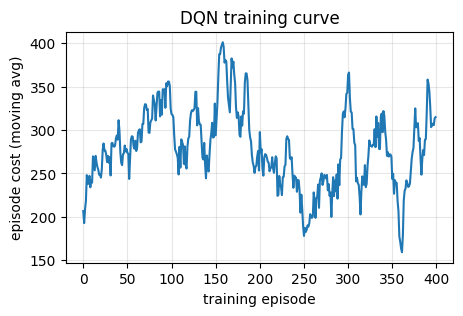

In [52]:
def policy_none(env): return 0
def policy_threshold(env):
    r = 100 * env.twin.smean.max(); return 0 if r <= 30 else (1 if r <= 70 else 3)

def expected_cost(twin, a, h=3, n=48, rng=None):
    rng = rng or np.random.default_rng(0); st = rng.random((n, NN)) < twin.b; st[:, I_NET] = True; tgt = twin.suspect(); act = twin.active_prob()
    iso = dict(rate=TTL if a == 2 else 0, block=TTL if a == 3 else 0, nodes={tgt: TTL} if a == 4 else {}); mult, drop = mods_for(a, tgt, iso, {tgt} if a == 5 else set())
    if a == 5: st[:, tgt] &= rng.random(n) > 0.9
    total = np.zeros(n); disr = C_DISRUPT * float((EW * drop).sum() / EW.sum()); down = (0.8 * CRIT[tgt] if a == 4 else 0.5 * CRIT[tgt] if a == 5 else 0.0)
    for k in range(h):
        total += DMG_RATE * (st * CRIT).sum(1); new = np.zeros_like(st)
        for e, (u, v, p) in enumerate(EDGE_LIST):
            if not twin.propagate and not INGRESS[e]: continue                                          # ablation: no topology-based spreading
            pe = p * mult[e] * (act if u == I_NET else 1.0)
            if pe > 0: new[:, v] |= st[:, u] & (rng.random(n) < pe)
        st |= new
    return float(total.mean() + FIXED[a] * (h if a in (2, 3, 4) else 1) + (disr + down) * (h if a in (2, 3, 4) else 1))

CAND = [0, 2, 3, 4, 5]
def policy_lookahead(env):
    tw = env.twin
    if tw.b[2:].max() < 0.02 and tw.q_in.max() < 0.1: return 0                                           # nothing suspicious -> skip the simulation
    costs = [expected_cost(tw, a, rng=np.random.default_rng(env.t)) for a in CAND]; return CAND[int(np.argmin(costs))]

class NumpyDQN:
    def __init__(self, sdim, adim, hid=64, lr=1e-3, gamma=0.95, seed=0):
        r = np.random.default_rng(seed); sz = [sdim, hid, hid, adim]
        self.W = [r.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sz[:-1], sz[1:])]; self.B = [np.zeros(b) for b in sz[1:]]
        self.tW, self.tB = [w.copy() for w in self.W], [b.copy() for b in self.B]; self.lr, self.gamma, self.r = lr, gamma, r
        self.mW = [np.zeros_like(w) for w in self.W]; self.vW = [np.zeros_like(w) for w in self.W]; self.mB = [np.zeros_like(b) for b in self.B]; self.vB = [np.zeros_like(b) for b in self.B]; self.k = 0
        self.buf = []; self.adim = adim
    def fwd(self, x, W=None, B=None):
        W, B = W or self.W, B or self.B; hs = [x]
        for i, (w, b) in enumerate(zip(W, B)): x = x @ w + b; x = np.maximum(x, 0) if i < len(W) - 1 else x; hs.append(x)
        return hs
    def q(self, s): return self.fwd(np.atleast_2d(s))[-1]
    def act(self, s, eps): return int(self.r.integers(self.adim)) if self.r.random() < eps else int(self.q(s)[0].argmax())
    def learn(self, bs=64):
        if len(self.buf) < bs: return
        idx = self.r.integers(0, len(self.buf), bs); S, A, R, S2, D = [np.array(x) for x in zip(*[self.buf[i] for i in idx])]
        y = R + self.gamma * self.fwd(S2, self.tW, self.tB)[-1].max(1) * (1 - D); hs = self.fwd(S); out = hs[-1]
        g = np.zeros_like(out); g[np.arange(bs), A] = (out[np.arange(bs), A] - y) / bs
        self.k += 1
        for i in range(len(self.W) - 1, -1, -1):
            gW = hs[i].T @ g; gB = g.sum(0)
            if i > 0: g = (g @ self.W[i].T) * (hs[i] > 0)
            for P, M, V, grad in ((self.W, self.mW, self.vW, gW), (self.B, self.mB, self.vB, gB)):
                M[i] = .9 * M[i] + .1 * grad; V[i] = .999 * V[i] + .001 * grad ** 2
                P[i] -= self.lr * (M[i] / (1 - .9 ** self.k)) / (np.sqrt(V[i] / (1 - .999 ** self.k)) + 1e-8)
    def sync(self): self.tW, self.tB = [w.copy() for w in self.W], [b.copy() for b in self.B]

N_TRAIN_EP = 40 if CFG["SMOKE_TEST"] else 400; N_EVAL_EP = 12 if CFG["SMOKE_TEST"] else 60
agent = NumpyDQN(NN + 3, NA, seed=CFG["SEED"]); step_ct = 0; ep_costs = []
for ep in range(N_TRAIN_EP):
    sc_ = sample_scenario(10_000 + ep, POOLS[("cal", "train")]); env = TwinEnv(sc_, POOLS[("cal", "train")], 10_000 + ep); s = env.reset(); eps = max(0.05, 1 - ep / (0.7 * N_TRAIN_EP))
    for _ in range(HORIZON):
        a = agent.act(s, eps); s2, r, d, _ = env.step(a); agent.buf.append((s, a, r / 10, s2, float(d))); s = s2; step_ct += 1
        if len(agent.buf) > 20000: agent.buf.pop(0)
        if step_ct > 200: agent.learn()
        if step_ct % 200 == 0: agent.sync()
        if d: break
    ep_costs.append(env.m["cost"])
plt.figure(figsize=(5, 3)); plt.plot(pd.Series(ep_costs).rolling(20, min_periods=1).mean()); plt.xlabel("training episode"); plt.ylabel("episode cost (moving avg)"); plt.title("DQN training curve"); plt.grid(alpha=.3); plt.show()
def policy_dqn(env): return int(agent.q(env.twin.state_vec(env.t))[0].argmax())

In [53]:
def run_episode(policy, seed, pools, twin_kwargs=None, obs_delay=0, keep_logs=False):
    sc_ = sample_scenario(seed, pools); env = TwinEnv(sc_, pools, seed, twin_kwargs, obs_delay); env.reset(); done = False
    while not done: _, _, done, _ = env.step(policy(env))
    out = env.summary(); out.update(scenario=sc_["name"], intensity=sc_["intensity"], seed=seed)
    return (out, env) if keep_logs else out

def evaluate(variants, seeds):
    rows = []
    for name, (pol, pools, tk) in variants.items():
        for sd in seeds: r = run_episode(pol, sd, pools, tk); r["policy"] = name; rows.append(r)
    return pd.DataFrame(rows)

def ci95(x): x = np.asarray(x, float); x = x[~np.isnan(x)]; return 1.96 * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
def summarize(df, cols=("total_cost", "damage", "comp_node_steps", "attack_blocked_frac", "benign_dropped_frac", "detect_delay", "recovery_steps"), ref=None):
    g = df.groupby("policy"); out = pd.DataFrame({c: g[c].mean() for c in cols}); out["cost_±95%CI"] = g["total_cost"].apply(ci95)
    if ref is not None:
        piv = df.pivot(index="seed", columns="policy", values="total_cost"); out["Wilcoxon_p_vs_" + ref] = [wilcoxon(piv[p], piv[ref]).pvalue if p != ref and not np.allclose(piv[p], piv[ref]) else np.nan for p in out.index]
    return out.sort_values("total_cost")

EVAL_SEEDS = list(range(N_EVAL_EP)); P_CAL, P_RAW = POOLS[("cal", "eval")], POOLS[("raw", "eval")]
pol_df = evaluate({"NoDefense": (policy_none, P_CAL, None), "ThresholdPolicy (30/70)": (policy_threshold, P_CAL, None),
                   "TwinLookahead": (policy_lookahead, P_CAL, None), "DQN": (policy_dqn, P_CAL, None)}, EVAL_SEEDS)
pol_tab = summarize(pol_df, ref="TwinLookahead"); RESULTS["policy_comparison"] = pol_tab; display(pol_tab.round(3))
display(pol_df.pivot_table(index="scenario", columns="policy", values="total_cost", aggfunc="mean").round(1))
print("All numbers are SIMULATED (software stand-in for the physical network). Lower cost is better; costs/weights are assumptions -> see sensitivity in §12.")

,total_cost,damage,comp_node_steps,attack_blocked_frac,benign_dropped_frac,detect_delay,recovery_steps,cost_±95%CI,Wilcoxon_p_vs_TwinLookahead
policy,,,,,,,,,
DQN,246.367,168.583,50.683,0.280,0.104,0.461,8.687,61.614,0.018
ThresholdPolicy (30/70),286.876,225.067,65.200,0.461,0.100,0.898,NaN,75.414,0.475
NoDefense,293.417,293.417,85.600,0.000,0.000,0.759,NaN,74.158,0.069
TwinLookahead,312.339,257.083,75.067,0.000,0.066,0.648,10.106,66.035,NaN


policy,DQN,NoDefense,ThresholdPolicy (30/70),TwinLookahead
scenario,,,,
benign_flash_crowd,30.8,0.0,4.1,60.1
botnet_iot_foothold,140.6,333.4,319.7,394.5
bruteforce_vpn_lateral,318.6,490.3,523.5,460.0
ddos_service_flood,131.7,72.0,111.3,100.4
dos_slow_web,141.3,70.0,127.8,117.0
multistage_apt,635.1,705.5,610.0,706.3
web_exploit_to_db,290.8,350.0,228.2,254.6


All numbers are SIMULATED (software stand-in for the physical network). Lower cost is better; costs/weights are assumptions -> see sensitivity in §12.


## 11. Formal Digital Twin definition and fidelity metrics
**Definition.** A cyber Digital Twin is the tuple **DT = ⟨G, b_t, 𝒪, U, F, π⟩** where
`G=(V,E,p)` is the attack graph, `b_t ∈ [0,1]^|V|` the belief that each node is compromised, `𝒪` the observation model (calibrated detector evidence `q_in, q_out` per monitoring cycle),
`U` the update `b_t = U(b_{t-1}, 𝒪_t)` (forgetting + noisy-OR propagation + evidence fusion), `F_h(b_t)` the h-step forecast, and `π(b_t)` the defense policy whose action is fed back to the physical system.
**Fidelity** is measured against the (simulated) hidden true state `x_t`:
state-sync error (Brier of `b_t` vs `x_t`, accuracy, AUROC), detection delay (cycles between true compromise and `b>0.5`), update latency (ms), observation-lag sensitivity, and h-step forecast quality.
In Colab the "physical system" is the simulator, so these numbers characterise the *twin algorithm*; on the Mininet testbed (§15) the same metrics are computed against the real emulated network.

In [54]:
def forecast_from(b, h):
    b = b.copy()
    for _ in range(h):
        nb = b.copy()
        for u, v, p in EDGE_LIST: nb[v] = 1 - (1 - nb[v]) * (1 - b[u] * p)
        b = nb
    return b

def fidelity(policy, seeds, pools, obs_delay=0):
    rows = []
    for sd in seeds:
        out, env = run_episode(policy, sd, pools, None, obs_delay, keep_logs=True); B = np.array(env.log_b)[:, 2:]; X = np.array(env.log_x)[:, 2:].astype(int)
        if X.max() == 0: continue
        r = dict(seed=sd, obs_delay=obs_delay, brier=((B - X) ** 2).mean(), acc=((B > .5).astype(int) == X).mean(), auroc=roc_auc_score(X.ravel(), B.ravel()) if len(np.unique(X)) == 2 else np.nan,
                 detect_delay=out["detect_delay"], update_ms=np.mean(env.twin.upd_ms))
        for h in (1, 2, 3):
            F = np.array([forecast_from(np.r_[1, 0, B[t]], h)[2:] for t in range(len(B) - h)]); Xh = X[h:]; r[f"forecast_brier_h{h}"] = ((F - Xh) ** 2).mean()
        rows.append(r)
    return pd.DataFrame(rows)

fid_df = pd.concat([fidelity(policy_none, EVAL_SEEDS, P_CAL, d) for d in (0, 1, 2)]); RESULTS["twin_fidelity"] = fid_df
display(fid_df.groupby("obs_delay").mean(numeric_only=True).drop(columns="seed").round(4))
print("Observation delay = cycles between the network and the twin's evidence. Fidelity should degrade gracefully as it grows. (policy = no defense, so the hidden state evolves freely.)")

,brier,acc,auroc,detect_delay,update_ms,forecast_brier_h1,forecast_brier_h2,forecast_brier_h3
obs_delay,,,,,,,,
0,0.2295,0.5966,0.8858,0.7590,0.0871,0.2901,0.3587,0.4244
1,0.2224,0.6098,0.8762,1.4152,0.0839,0.2794,0.3436,0.4069
2,0.2175,0.6210,0.8652,2.1370,0.1185,0.2708,0.3305,0.3912


Observation delay = cycles between the network and the twin's evidence. Fidelity should degrade gracefully as it grows. (policy = no defense, so the hidden state evolves freely.)


## 12. Ablation, sensitivity and statistics
Full system = calibrated scores + topology propagation + temporal (trend) forecast + twin look-ahead policy. Each variant removes **one** component; all variants see the same scenario seeds (paired). Cost = simulated, lower is better.

In [55]:
Dfull = dict(propagate=True, trend=True)
abl_df = evaluate({"Full system": (policy_lookahead, P_CAL, Dfull),
                   "– calibration (raw scores)": (policy_lookahead, P_RAW, Dfull),
                   "– topology propagation": (policy_lookahead, P_CAL, dict(propagate=False, trend=True)),
                   "– temporal forecast": (policy_lookahead, P_CAL, dict(propagate=True, trend=False)),
                   "– adaptive defense (fixed thresholds)": (policy_threshold, P_CAL, Dfull),
                   "DQN instead of look-ahead": (policy_dqn, P_CAL, Dfull),
                   "No defense": (policy_none, P_CAL, Dfull)}, EVAL_SEEDS)
abl_tab = summarize(abl_df, ref="Full system"); RESULTS["ablation"] = abl_tab; display(abl_tab.round(3))
print("Interpretation rule: a component 'matters' only if removing it raises cost with a small Wilcoxon p AND the CI does not overlap. If a variant is not worse, say so — that is a legitimate finding.")

# cost-parameter sensitivity (are the conclusions an artefact of C_DISRUPT?)
rows = []; C0 = C_DISRUPT
for c in (4.0, 8.0, 16.0):
    C_DISRUPT = c; d = evaluate({"ThresholdPolicy": (policy_threshold, P_CAL, None), "TwinLookahead": (policy_lookahead, P_CAL, None), "DQN": (policy_dqn, P_CAL, None), "NoDefense": (policy_none, P_CAL, None)}, EVAL_SEEDS[:max(8, len(EVAL_SEEDS) // 2)])
    rows += [dict(C_DISRUPT=c, policy=k, total_cost=v) for k, v in d.groupby("policy").total_cost.mean().items()]
C_DISRUPT = C0; sens_c = pd.DataFrame(rows).pivot(index="C_DISRUPT", columns="policy", values="total_cost"); RESULTS["cost_sensitivity"] = sens_c; display(sens_c.round(1))

,total_cost,damage,comp_node_steps,attack_blocked_frac,benign_dropped_frac,detect_delay,recovery_steps,cost_±95%CI,Wilcoxon_p_vs_Full system
policy,,,,,,,,,
DQN instead of look-ahead,246.367,168.583,50.683,0.280,0.104,0.461,8.687,61.614,0.018
– topology propagation,276.184,253.117,74.183,0.000,0.021,3.700,14.192,71.330,0.000
– adaptive defense (fixed thresholds),286.876,225.067,65.200,0.461,0.100,0.898,NaN,75.414,0.475
– calibration (raw scores),291.197,237.533,70.383,0.000,0.065,0.719,10.175,62.914,0.230
No defense,293.417,293.417,85.600,0.000,0.000,0.759,NaN,74.158,0.069
– temporal forecast,304.022,249.683,73.517,0.000,0.065,1.089,10.158,65.663,0.495
Full system,312.339,257.083,75.067,0.000,0.066,0.648,10.106,66.035,NaN


Interpretation rule: a component 'matters' only if removing it raises cost with a small Wilcoxon p AND the CI does not overlap. If a variant is not worse, say so — that is a legitimate finding.


policy,DQN,NoDefense,ThresholdPolicy,TwinLookahead
C_DISRUPT,,,,
4.0,241.8,306.4,291.3,283.9
8.0,257.7,306.4,315.9,329.9
16.0,289.6,306.4,365.3,312.9


### 12.1 Larger defense evaluation (more episodes, paired tests, DQN retrained with other seeds)
The main run in §10.1 uses few episodes and one DQN training run, so the confidence intervals overlap. Here every policy is evaluated on a larger set of **new, never-used episode seeds** (training episodes use seeds ≥ 10,000, evaluation in §10.1 uses 0–59). Comparisons are **paired** (same scenario instance for every policy), with a bootstrap CI of the mean cost difference and Holm-corrected Wilcoxon p-values. The DQN is also retrained with different random seeds, because a single RL training run is not evidence of a stable result.

`N_EVAL_BIG` and `RETRAIN_DQN_SEEDS` control the run time; lower them if the cell is too slow. All numbers remain **simulated**.


In [56]:
from scipy.stats import wilcoxon
N_EVAL_BIG = 12 if CFG["SMOKE_TEST"] else 200               # evaluation episodes per policy
RETRAIN_DQN_SEEDS = [] if CFG["SMOKE_TEST"] else [1, 2]    # extra DQN training seeds ([] = skip; each costs about as much as the DQN training in §10.1)
BIG_SEEDS = list(range(1000, 1000 + N_EVAL_BIG))           # disjoint from training (>=10,000) and from §10.1 evaluation (0..59)

def train_dqn(seed, n_ep=None):
    n_ep = n_ep or N_TRAIN_EP; ag = NumpyDQN(NN + 3, NA, seed=seed); sc = 0
    for ep in range(n_ep):
        es = 10_000 + 1000 * seed + ep; sc_ = sample_scenario(es, POOLS[("cal", "train")]); env = TwinEnv(sc_, POOLS[("cal", "train")], es)
        s = env.reset(); eps = max(0.05, 1 - ep / (0.7 * n_ep))
        for _ in range(HORIZON):
            a = ag.act(s, eps); s2, r, d, _ = env.step(a); ag.buf.append((s, a, r / 10, s2, float(d))); s = s2; sc += 1
            if len(ag.buf) > 20000: ag.buf.pop(0)
            if sc > 200: ag.learn()
            if sc % 200 == 0: ag.sync()
            if d: break
    return ag
def dqn_policy(ag): return lambda env: int(ag.q(env.twin.state_vec(env.t))[0].argmax())

variants = {"NoDefense": (policy_none, P_CAL, None), "ThresholdPolicy (30/70)": (policy_threshold, P_CAL, None),
            "TwinLookahead": (policy_lookahead, P_CAL, None), f"DQN (train seed {CFG['SEED']})": (policy_dqn, P_CAL, None)}
for sd in RETRAIN_DQN_SEEDS: variants[f"DQN (train seed {sd})"] = (dqn_policy(train_dqn(sd)), P_CAL, None)
big_df = evaluate(variants, BIG_SEEDS)
big_tab = summarize(big_df, ref="NoDefense"); RESULTS["policy_comparison_large"] = big_tab; display(big_tab.round(3))

# paired differences (A - B): negative = A is cheaper
piv = big_df.pivot(index="seed", columns="policy", values="total_cost"); dq = [c for c in piv.columns if c.startswith("DQN")]
pairs = [(d_, "NoDefense") for d_ in dq] + [(d_, "ThresholdPolicy (30/70)") for d_ in dq] + [(d_, "TwinLookahead") for d_ in dq] \
        + [("TwinLookahead", "NoDefense"), ("ThresholdPolicy (30/70)", "NoDefense")]
rows = []
for a, b in pairs:
    diff = (piv[a] - piv[b]).values; rng_b = np.random.default_rng(0)
    boots = [diff[rng_b.integers(0, len(diff), len(diff))].mean() for _ in range(2000)]
    p = wilcoxon(piv[a], piv[b]).pvalue if not np.allclose(diff, 0) else np.nan
    rows.append(dict(A=a, B=b, mean_cost_diff_A_minus_B=diff.mean(), ci95_low=np.percentile(boots, 2.5), ci95_high=np.percentile(boots, 97.5), A_cheaper_in_frac=(diff < 0).mean(), wilcoxon_p=p))
pair_df = pd.DataFrame(rows)
order = np.argsort(pair_df["wilcoxon_p"].fillna(1).values); m_ = len(pair_df); holm = np.ones(m_); run_max = 0.0       # Holm step-down
for rank, i in enumerate(order):
    run_max = max(run_max, min(1.0, (m_ - rank) * float(np.nan_to_num(pair_df["wilcoxon_p"].iloc[i], nan=1.0)))); holm[i] = run_max
pair_df["p_holm"] = holm; RESULTS["policy_pairwise_large"] = pair_df; display(pair_df.round(4))
print("A difference is supported only if the bootstrap CI excludes 0 AND p_holm < 0.05. Otherwise report it as 'not distinguishable from zero'.")

# per scenario: who wins, and how many episodes each scenario got
sc_cost = big_df.pivot_table(index="scenario", columns="policy", values="total_cost", aggfunc="mean"); sc_cost["n_episodes"] = big_df.groupby("scenario")["seed"].nunique()
sc_cost["cheapest"] = sc_cost.drop(columns="n_episodes").idxmin(axis=1); RESULTS["policy_by_scenario_large"] = sc_cost; display(sc_cost.round(1))
dqn_cols = [c for c in piv.columns if c.startswith("DQN")]
if len(dqn_cols) > 1: print("DQN mean cost across training seeds:", {c: round(float(piv[c].mean()), 1) for c in dqn_cols}, "| spread across seeds is part of the uncertainty.")


,total_cost,damage,comp_node_steps,attack_blocked_frac,benign_dropped_frac,detect_delay,recovery_steps,cost_±95%CI,Wilcoxon_p_vs_NoDefense
policy,,,,,,,,,
ThresholdPolicy (30/70),243.865,173.485,49.460,0.607,0.114,0.765,NaN,37.182,0.018
DQN (train seed 42),253.755,168.005,50.440,0.319,0.116,0.435,9.472,31.545,0.771
DQN (train seed 2),259.475,213.700,63.275,0.215,0.062,0.495,6.784,33.192,0.550
DQN (train seed 1),261.354,203.610,59.970,0.072,0.069,0.314,6.790,32.214,0.532
TwinLookahead,282.157,231.410,68.415,0.000,0.060,0.735,9.431,33.066,0.380
NoDefense,290.845,290.845,85.140,0.000,0.000,0.614,NaN,38.605,NaN


,A,B,mean_cost_diff_A_minus_B,ci95_low,ci95_high,A_cheaper_in_frac,wilcoxon_p,p_holm
0,DQN (train seed 1),NoDefense,-29.4911,-47.0668,-12.9506,0.395,0.5322,1.0000
1,DQN (train seed 2),NoDefense,-31.3699,-47.7800,-15.9474,0.340,0.5499,1.0000
2,DQN (train seed 42),NoDefense,-37.0900,-64.2368,-11.7013,0.380,0.7706,1.0000
3,DQN (train seed 1),ThresholdPolicy (30/70),17.4886,-12.8977,49.9159,0.455,0.9097,1.0000
4,DQN (train seed 2),ThresholdPolicy (30/70),15.6098,-11.9022,44.3319,0.480,0.6446,1.0000
5,DQN (train seed 42),ThresholdPolicy (30/70),9.8897,-22.5095,40.2505,0.365,0.0297,0.2374
6,DQN (train seed 1),TwinLookahead,-20.8026,-35.5599,-6.1660,0.645,0.0010,0.0101
7,DQN (train seed 2),TwinLookahead,-22.6814,-38.0902,-8.2914,0.685,0.0000,0.0002
8,DQN (train seed 42),TwinLookahead,-28.4015,-51.3414,-7.6752,0.545,0.0513,0.3589
9,TwinLookahead,NoDefense,-8.6885,-23.0242,4.7389,0.385,0.3801,1.0000


A difference is supported only if the bootstrap CI excludes 0 AND p_holm < 0.05. Otherwise report it as 'not distinguishable from zero'.


policy,DQN (train seed 1),DQN (train seed 2),DQN (train seed 42),NoDefense,ThresholdPolicy (30/70),TwinLookahead,n_episodes,cheapest
scenario,,,,,,,,
benign_flash_crowd,19.6,6.9,28.7,0.0,3.2,54.4,31,NoDefense
botnet_iot_foothold,244.7,263.5,234.6,303.0,180.6,258.2,30,ThresholdPolicy (30/70)
bruteforce_vpn_lateral,401.8,453.3,354.3,500.6,405.5,452.0,23,DQN (train seed 42)
ddos_service_flood,103.9,89.6,140.0,69.9,115.4,111.9,27,NoDefense
dos_slow_web,119.8,85.6,134.6,69.3,107.9,105.5,35,NoDefense
multistage_apt,576.6,580.8,557.6,707.0,533.4,635.4,30,ThresholdPolicy (30/70)
web_exploit_to_db,449.4,437.9,394.0,501.8,459.7,451.1,24,DQN (train seed 42)


DQN mean cost across training seeds: {'DQN (train seed 1)': 261.4, 'DQN (train seed 2)': 259.5, 'DQN (train seed 42)': 253.8} | spread across seeds is part of the uncertainty.


## 13. Adversarial robustness
Tree models are not differentiable, so (i) a differentiable **surrogate MLP** is attacked with white-box FGSM/PGD in the scaled feature space, (ii) the adversarial flows are **transferred** to LightGBM/RF trained on the same features, (iii) **label-flipping poisoning**, (iv) **adversarial training** of the surrogate.
⚠ Perturbations are in scaled feature space and do **not** enforce protocol consistency (e.g. bytes vs packets), so they are an *upper bound* on a real attacker's power. A constrained, problem-space attack is future work.

In [57]:
rng_a = np.random.default_rng(0); sub_i = rng_a.choice(tr, min(len(tr), 20000), replace=False)
pre_a = make_preproc("scaled", CFG["N_FEATURES"]); Za = pre_a.fit_transform(make_X(DF.iloc[sub_i], False), DF["y"].values[sub_i]); ya_ = DF["y"].values[sub_i]
Zt = pre_a.transform(make_X(TE, False)); lo_, hi_ = Za.min(0), Za.max(0); att = np.where(yt == 1)[0][:2000]
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=80, early_stopping=True, random_state=0).fit(Za, ya_)
lg_a = lgb.LGBMClassifier(n_estimators=150, verbose=-1, random_state=0, n_jobs=-1).fit(Za, ya_); rf_a = RandomForestClassifier(n_estimators=60, n_jobs=-1, random_state=0).fit(Za, ya_)

def grad_loss(m, X, y):
    hs = [X]; h = X
    for i, (w, b) in enumerate(zip(m.coefs_, m.intercepts_)): h = h @ w + b; h = np.maximum(h, 0) if i < len(m.coefs_) - 1 else h; hs.append(h)
    p = 1 / (1 + np.exp(-hs[-1][:, 0])); g = (p - y)[:, None]
    for i in range(len(m.coefs_) - 1, -1, -1):
        gx = g @ m.coefs_[i].T
        if i > 0: g = gx * (hs[i] > 0)
    return gx
def fgsm(m, X, y, eps): return np.clip(X + eps * np.sign(grad_loss(m, X, y)), lo_, hi_)
def pgd(m, X, y, eps, steps=10):
    A = X.copy()
    for _ in range(steps): A = np.clip(np.clip(A + eps / 4 * np.sign(grad_loss(m, A, y)), X - eps, X + eps), lo_, hi_)
    return A
rec = lambda mdl, X: float((mdl.predict_proba(X)[:, 1] >= .5).mean())
Xc = Zt[att]; yc = np.ones(len(att)); rows = [dict(attack="none (clean)", eps=0, MLP_surrogate=rec(mlp, Xc), LightGBM=rec(lg_a, Xc), RandomForest=rec(rf_a, Xc))]
for eps in (0.1, 0.25, 0.5, 1.0):
    for nm, A in (("random noise", np.clip(Xc + eps * rng_a.choice([-1, 1], Xc.shape), lo_, hi_)), ("FGSM", fgsm(mlp, Xc, yc, eps)), ("PGD-10", pgd(mlp, Xc, yc, eps))):
        rows.append(dict(attack=nm, eps=eps, MLP_surrogate=rec(mlp, A), LightGBM=rec(lg_a, A), RandomForest=rec(rf_a, A)))
adv_tab = pd.DataFrame(rows); RESULTS["adversarial_evasion"] = adv_tab; print("Attack-flow RECALL under evasion (lower = attacker wins):"); display(adv_tab.round(3))

rows = []
for rate in (0.0, 0.05, 0.10, 0.20):
    y_p = ya_.copy(); flip = (rng_a.random(len(y_p)) < rate) & (y_p == 1); y_p[flip] = 0
    m = lgb.LGBMClassifier(n_estimators=150, verbose=-1, random_state=0, n_jobs=-1).fit(Za, y_p); s = m.predict_proba(Zt)[:, 1]; r_ = binary_metrics(yt, s)
    rows.append(dict(poison_rate_of_attack_labels=rate, recall=r_["rec"], precision=r_["prec"], pr_auc=r_["pr_auc"], mcc=r_["mcc"]))
poison_tab = pd.DataFrame(rows); RESULTS["poisoning"] = poison_tab; display(poison_tab.round(3))

adv_tr = pgd(mlp, Za[ya_ == 1], np.ones((ya_ == 1).sum()), 0.5); Zat = np.vstack([Za, adv_tr]); yat = np.r_[ya_, np.ones(len(adv_tr))]
mlp_at = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=80, early_stopping=True, random_state=0).fit(Zat, yat)
for nm, m in (("standard MLP", mlp), ("adversarially trained MLP", mlp_at)):
    print(f"{nm:<28} clean recall {rec(m, Xc):.3f} | PGD eps=0.5 white-box recall {rec(m, pgd(m, Xc, yc, 0.5)):.3f} | clean F1 {binary_metrics(yt, m.predict_proba(Zt)[:, 1])['f1']:.3f}")

Attack-flow RECALL under evasion (lower = attacker wins):


,attack,eps,MLP_surrogate,LightGBM,RandomForest
0,none (clean),0.00,0.953,0.953,0.946
1,random noise,0.10,0.938,0.240,0.334
2,FGSM,0.10,0.153,0.212,0.132
3,PGD-10,0.10,0.152,0.198,0.140
4,random noise,0.25,0.758,0.258,0.223
5,FGSM,0.25,0.024,0.160,0.070
6,PGD-10,0.25,0.024,0.167,0.106
7,random noise,0.50,0.611,0.276,0.236
8,FGSM,0.50,0.000,0.094,0.164
9,PGD-10,0.50,0.000,0.157,0.088


,poison_rate_of_attack_labels,recall,precision,pr_auc,mcc
0,0.00,0.852,0.967,0.963,0.842
1,0.05,0.851,0.970,0.963,0.844
2,0.10,0.849,0.974,0.961,0.846
3,0.20,0.837,0.983,0.960,0.844


standard MLP                 clean recall 0.953 | PGD eps=0.5 white-box recall 0.000 | clean F1 0.902
adversarially trained MLP    clean recall 0.956 | PGD eps=0.5 white-box recall 0.000 | clean F1 0.903


## 14. Streaming latency, throughput and scalability
Kafka/Flink are not available in Colab. Instead: a **trace-driven queueing simulation** — flows arrive as a Poisson process at a chosen rate, are micro-batched, and every batch is **really scored** by the pipeline; the *measured* service time drives the queue (no sleeping). This yields honest p50/p95/p99 end-to-end latency and saturation points for *this* machine. Report the hardware.

In [58]:
import psutil
def stream_sim(det, pool_df, rate, batch, n=2000, max_wait=0.05, seed=0):
    r = np.random.default_rng(seed); arr = np.cumsum(r.exponential(1 / rate, n)); fl = pool_df.iloc[r.integers(0, len(pool_df), n)].reset_index(drop=True)
    i, t_free, lat, svc_tot = 0, 0.0, [], 0.0
    while i < n:
        t_start = max(t_free, arr[i]); deadline = max(t_start, arr[i] + max_wait); j = i + int(np.searchsorted(arr[i:i + batch], deadline, side="right"))
        ready = arr[j - 1] if j - i == batch else deadline; t0 = max(t_free, ready)
        c = time.perf_counter(); det.proba(fl.iloc[i:j]); svc = time.perf_counter() - c; svc_tot += svc
        done = t0 + svc; lat += list(done - arr[i:j]); t_free = done; i = j
    lat = np.array(lat) * 1e3
    return dict(rate_fps=rate, batch=batch, p50_ms=np.percentile(lat, 50), p95_ms=np.percentile(lat, 95), p99_ms=np.percentile(lat, 99), achieved_fps=n / (t_free - arr[0]), cpu_busy=svc_tot / (t_free - arr[0]))

grid = [(200, 1), (200, 32), (1000, 32), (1000, 256), (5000, 256), (20000, 256)]
lat_tab = pd.DataFrame([stream_sim(primary, TE, r_, b_, n=800 if CFG["SMOKE_TEST"] else 3000) for r_, b_ in grid]); RESULTS["streaming_latency"] = lat_tab; display(lat_tab.round(2))
tw_ = DigitalTwin(); tw_.reset(); tw_.b[2:] = 0.4; tw_.q_in[:] = 0.3; t = time.perf_counter()
for _ in range(10): [expected_cost(tw_, a_) for a_ in CAND]
dec_ms = (time.perf_counter() - t) / 10 * 1e3          # one full decision = 5 candidate actions x Monte-Carlo roll-out
print(f"twin look-ahead decision ≈ {dec_ms:.1f} ms | hardware: {psutil.cpu_count()} vCPU, {psutil.virtual_memory().total/2**30:.1f} GB RAM, RSS now {psutil.Process().memory_info().rss/2**30:.2f} GB")
print("Detection-to-defense delay ≈ p95 latency of the chosen row + the decision time above. If achieved_fps < rate_fps the system is saturated (queue grows).")

# network-size scaling of the propagation model
rows = []
for n in (10, 50, 100, 300, 1000):
    Gs = nx.gnp_random_graph(n, min(1.0, 3 / n), seed=1, directed=True)
    for u, v in Gs.edges: Gs[u][v]["p"] = 0.3
    t = time.perf_counter(); cascade_prob(Gs, sources=(0,), n_sims=500, rng=np.random.default_rng(0)); rows.append(dict(nodes=n, edges=Gs.number_of_edges(), seconds=time.perf_counter() - t, rss_gb=psutil.Process().memory_info().rss / 2 ** 30))
scale_tab = pd.DataFrame(rows); RESULTS["scalability"] = scale_tab; display(scale_tab.round(3))

,rate_fps,batch,p50_ms,p95_ms,p99_ms,achieved_fps,cpu_busy
0,200,1,22512.59,43440.68,44937.16,49.56,1.00
1,200,32,48.72,73.43,81.59,196.58,0.37
2,1000,32,106.29,236.18,252.38,970.01,0.94
3,1000,256,44.26,66.36,68.07,973.21,0.35
4,5000,256,47.12,68.92,76.11,4515.63,0.42
5,20000,256,69.58,111.61,116.90,11454.51,0.95


twin look-ahead decision ≈ 2.7 ms | hardware: 2 vCPU, 12.7 GB RAM, RSS now 1.34 GB
Detection-to-defense delay ≈ p95 latency of the chosen row + the decision time above. If achieved_fps < rate_fps the system is saturated (queue grows).


,nodes,edges,seconds,rss_gb
0,10,26,0.002,1.342
1,50,153,0.009,1.342
2,100,309,0.026,1.342
3,300,921,0.087,1.342
4,1000,2947,0.371,1.342


## 15. Live testbed path (Mininet + Open vSwitch)
Colab has no OVS kernel datapath, so **no live result is claimed here**. The cell below exports a "lite" model that only uses features a packet sniffer can compute; `mininet_testbed.py` (next to this notebook, **not executed in this notebook**) runs on a Linux VM with Mininet/OVS, sniffs the switch port, scores flows, installs/rolls back OVS drop rules, and logs detection delay, attack packets before/after the block, and benign-request success.
Domain shift warning: the sniffer's features are *approximations* of CICFlowMeter's, so retraining on locally captured traffic is required before claiming testbed accuracy.

In [59]:
import joblib
LITE = ["Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts", "TotLen Fwd Pkts", "TotLen Bwd Pkts", "Fwd Pkt Len Max", "Fwd Pkt Len Min", "Fwd Pkt Len Mean", "Fwd Pkt Len Std",
        "Bwd Pkt Len Max", "Bwd Pkt Len Min", "Bwd Pkt Len Mean", "Bwd Pkt Len Std", "Flow Byts/s", "Flow Pkts/s", "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min", "Fwd Pkts/s", "Bwd Pkts/s"]
LITE = [c for c in LITE if c in DF.columns]
lite = Pipeline([("imp", SimpleImputer(strategy="median", keep_empty_features=True)), ("clf", lgb.LGBMClassifier(n_estimators=150, class_weight="balanced", verbose=-1, random_state=42, n_jobs=-1))])
lite.fit(DF.iloc[tr][LITE].replace([np.inf, -np.inf], np.nan), DF["y"].values[tr]); s_l = lite.predict_proba(TE[LITE].replace([np.inf, -np.inf], np.nan))[:, 1]
print("lite model (sniffer-computable features) PR-AUC on held-out time:", round(binary_metrics(yt, s_l)["pr_auc"], 4), "| features:", len(LITE))
joblib.dump(dict(model=lite, features=LITE), os.path.join(CFG["OUT_DIR"], "lite_model.joblib"))

lite model (sniffer-computable features) PR-AUC on held-out time: 0.9539 | features: 21


['/content/dt_outputs/lite_model.joblib']

## 16. Reproducibility package

In [60]:
import importlib.metadata as md
for k, v in RESULTS.items():
    try: (v if isinstance(v, (pd.DataFrame, pd.Series)) else pd.DataFrame(v)).to_csv(os.path.join(CFG["OUT_DIR"], f"{k}.csv"))
    except Exception as e: print("not saved:", k, e)
joblib.dump(primary, os.path.join(CFG["OUT_DIR"], "primary_detector.joblib")); joblib.dump(fam_model, os.path.join(CFG["OUT_DIR"], "family_model.joblib"))
vers = {p: md.version(p) for p in ("numpy", "pandas", "scikit-learn", "lightgbm", "xgboost", "shap", "lime", "networkx", "scipy", "statsmodels", "imbalanced-learn") if True}
json.dump(dict(config=CFG, python=platform.python_version(), versions=vers, cost_params=dict(C_DISRUPT=C_DISRUPT, DMG_RATE=DMG_RATE, TTL=TTL, HORIZON=HORIZON, FIXED=FIXED.tolist()), risk_weights=RISK_W, severity=SEV, primary=PRIMARY),
          open(os.path.join(CFG["OUT_DIR"], "run_config.json"), "w"), indent=2, default=str)
open(os.path.join(CFG["OUT_DIR"], "requirements.txt"), "w").write("\n".join(f"{p}=={v}" for p, v in vers.items()) + "\n")
open(os.path.join(CFG["OUT_DIR"], "Dockerfile"), "w").write("FROM python:3.11-slim\nWORKDIR /app\nCOPY requirements.txt .\nRUN pip install --no-cache-dir -r requirements.txt jupyter matplotlib seaborn psutil\nCOPY . .\nCMD [\"jupyter\", \"nbconvert\", \"--to\", \"notebook\", \"--execute\", \"AI_Cybersecurity_Digital_Twin_v2.ipynb\"]\n")
print("Saved to", CFG["OUT_DIR"], ":", sorted(os.listdir(CFG["OUT_DIR"]))[:12], "...")
print("Seeds: CFG['SEED'] + split/pool seeds are fixed in code. Publish: notebook, mininet_testbed.py, this folder, dataset download script (§1), and the exact CIC file names used.")

Saved to /content/dt_outputs : ['Dockerfile', 'ablation.csv', 'adversarial_evasion.csv', 'baselines.csv', 'calibration.csv', 'cost_sensitivity.csv', 'early_warning.csv', 'family_model.joblib', 'imbalance_handling.csv', 'leakage_study.csv', 'lite_model.joblib', 'lodo.csv'] ...
Seeds: CFG['SEED'] + split/pool seeds are fixed in code. Publish: notebook, mininet_testbed.py, this folder, dataset download script (§1), and the exact CIC file names used.


## 17. Conclusion

**What was done.** The five-stage Project 16 pipeline (Current Network State → Digital Twin → Attack Simulation → Risk Prediction → Defense Strategy) was implemented on CSE-CIC-IDS2018 (5 training days, 6 families, up to 5,000 flows per day and family) with a 14-node twin. Every stage was evaluated with an explicit protocol, and results that did not support the original design are reported as such.

**Main findings**
1. **The evaluation protocol matters most.** The legacy protocol (leaky fit, random split, single day) gave 99.85 % on Fri-02. A leakage-safe chronological split gave 97.1 %, and the pooled multi-day binary task gave 90.4 % accuracy (MCC 0.805, FPR 6.3 %). The random split, not scaler leakage, caused most of the inflation. **H1 (leakage-safe, chronological evaluation lowers headline accuracy) is supported.**
2. **Unseen attack families are largely missed.** In leave-one-day-out testing, LightGBM reached a mean PR-AUC of 0.722 but a mean F1 of 0.165 and recall of 0.103 (large standard deviations, 5 families). Infiltration was the hardest family (F1 0.396 in the multi-class report).
3. **A new day alone breaks the detector, even for a known family (§3.2).** On Fri-16 (DoS, other tool variants than the Thu-15 training data), LightGBM ranks flows well (PR-AUC 0.993 vs 0.722 when DoS was unseen) but at the default threshold it flags 90 % of benign flows (FPR 0.905, F1 0.686, MCC 0.206); RandomForest gives PR-AUC 0.718, recall 0.511, FPR 0.255. On Thu-01 (Infiltration, seen on Wed-28) there is no gain at all (LightGBM PR-AUC 0.550 vs 0.626 unseen, recall 0.179). The weak transfer is therefore not explained by the family being unseen alone; it reflects day-, tool- and attacker-specific shifts, and fixed thresholds do not transfer.
4. **Precision collapses at realistic prevalence.** At a fixed FPR of 3.05 %, precision falls from 0.958 (50 % attacks) to 0.222 (1 % attacks).
5. **Model choice.** LightGBM, XGBoost, RandomForest and MLP were close (PR-AUC 0.952–0.965); LightGBM and XGBoost were not significantly different (McNemar p = 0.13). The unsupervised detectors were weak (F1 0.36 and 0.07). Seed variance was negligible (std ≤ 0.0016).
6. **Calibration and explanation.** Isotonic calibration reduced ECE from 0.056 to 0.026. SHAP and permutation importance both ranked a TCP-window feature (Init Fwd Win Byts) first (Spearman 0.556), which suggests a tool or OS fingerprint and is consistent with the poor transfer in finding 3.
7. **Graph-based risk differs from a fixed decay.** CVSS-derived propagation ranks nodes very differently from a uniform 0.70 edge probability (Spearman 0.334; 2.8 vs 5.2 expected compromised nodes). The node ranking is stable under parameter noise (mean ρ 0.921), while absolute risk depends strongly on the prior. DMZ nodes (VPN-GW, LoadBalancer, Web-1/2) rank highest.
8. **Defense (simulated): no learned or twin-guided policy beat a simple threshold.** In the 60-episode run (§10.1) DQN had the lowest mean cost (246 vs 293 without defense) but with overlapping confidence intervals. With 200 paired episodes and three DQN training seeds (§12.1) the ordering changed: fixed thresholds 243.9, DQN 253.8 / 259.5 / 261.4, twin look-ahead 282.2, no defense 290.8. DQN lowered the mean cost relative to no defense by 29–37 (bootstrap CI excludes 0) but was cheaper in only 34–40 % of episodes, and no difference against no defense survived Holm-corrected Wilcoxon tests; DQN and the thresholds were not distinguishable. The twin look-ahead was not distinguishable from no defense (difference −8.7, CI −23.0 to +4.7) and blocked no attack traffic, while DQN beat it in two of three training seeds (p_holm 0.010 and 0.0002). The best policy depends on the scenario: no defense was cheapest for the benign flash crowd, DDoS flood and slow DoS (defensive actions cost more than the damage), thresholds for the IoT botnet and multi-stage APT, DQN (seed 42) for VPN brute force and web-exploit-to-DB. **H2 (twin-guided policy lowers cost versus fixed thresholds) is not supported.**
9. **Ablation.** Removing calibration, topology propagation or the temporal term did not make the full system worse; the full look-ahead system had the highest cost of all variants in §12 (312 vs 276–304). **H3 (each twin component contributes measurably) is not supported** in this simulator.
10. **Forecasting.** Next-window attack prediction on Fri-02 reached F1 0.944–0.964 for all methods, with a persistence baseline close to the best learned model (F1 0.944, PR-AUC 0.915 vs MLP 0.945), and the early-warning lead-time table was empty because too few attack onsets were available. The "predictive" claim is therefore not demonstrated here.
11. **Runtime.** Batched inference sustained about 9.8 k flows/s (p95 154 ms at batch 256), while one-flow-at-a-time inference saturated near 44 flows/s. Propagation on a 1,000-node graph took 0.41 s.

**Limitations**
- The training data hold each attack family on one day (two further days, Fri-16 and Thu-01, were used for testing only), and 5,000 flows per day and family were sampled.
- Topology, CVSS scores, criticality and action costs are assumptions, not measurements.
- Defense, closed-loop and fidelity results are simulated; Mininet/OVS was not run live. The twin's state estimate was only moderately faithful (AUROC 0.87–0.89).
- The CIC-IDS2017 cross-dataset test (§3.3) is implemented but was not run because no 2017 file was available.
- The detectors are highly vulnerable to evasion: FGSM/PGD at ε = 0.1 reduced attack recall to about 0.13–0.21, and adversarial training did not help at ε = 0.5, whereas poisoning of up to 20 % of attack labels had little effect.

**Future work.** Run the CIC-IDS2017 cross-dataset test, learn edge probabilities and action costs from real attack logs, run the Mininet/OVS testbed to measure real defense effects, make the decision threshold adapt to day-to-day shifts in benign traffic, and harden the detector against evasion.
